Mengunduh data historis BTC-USD 5 Tahun...


[*********************100%***********************]  1 of 1 completed
Beginning AutoGluon training... Time limit = 300s
AutoGluon will save models to '/Applications/MAMP/htdocs/local/kodingakademi/Python/python 4/bootcamp batch 3/final/AutogluonModels/ag-20260511_154811'
=================== System Info ===================
AutoGluon Version:  1.5.0
Python Version:     3.12.7
Operating System:   Darwin
Platform Machine:   arm64
Platform Version:   Darwin Kernel Version 25.2.0: Tue Nov 18 21:03:25 PST 2025; root:xnu-12377.61.12~1/RELEASE_ARM64_T8122
CPU Count:          8
Pytorch Version:    2.9.1
CUDA Version:       CUDA is not available
GPU Count:          WARNING: Exception was raised when calculating GPU count (AssertionError)
Memory Avail:       1.45 GB / 8.00 GB (18.2%)
Disk Space Avail:   14.31 GB / 228.27 GB (6.3%)
Setting presets to: high_quality

Fitting with arguments:
{'enable_ensemble': True,
 'eval_metric': MAPE,
 'freq': 'D',
 'hyperparameters': 'default',
 'known_covariates_


Total Data setelah Feature Engineering: 1798 Hari

Melatih model...


	-0.1923       = Validation score (-MAPE)
	1.18    s     = Training runtime
	0.32    s     = Validation (prediction) runtime
Training timeseries model DirectTabular. Training for up to 33.2s of the 298.4s of remaining time.
	-0.5977       = Validation score (-MAPE)
	0.91    s     = Training runtime
	0.03    s     = Validation (prediction) runtime
Training timeseries model DynamicOptimizedTheta. Training for up to 37.2s of the 297.4s of remaining time.
	-0.1854       = Validation score (-MAPE)
	0.01    s     = Training runtime
	0.26    s     = Validation (prediction) runtime
Training timeseries model Chronos2. Training for up to 42.4s of the 297.1s of remaining time.


model.safetensors:   0%|          | 0.00/478M [00:00<?, ?B/s]

...

	Time limit exceeded... Skipping Chronos2SmallFineTuned.
Training timeseries model AutoETS. Training for up to 33.2s of the 165.8s of remaining time.
	-0.1819       = Validation score (-MAPE)
	0.01    s     = Training runtime
	0.32    s     = Validation (prediction) runtime
Training timeseries model ChronosWithRegressor[bolt_small]. Training for up to 41.4s of the 165.5s of remaining time.
	Skipping covariate_regressor since the dataset contains no known_covariates or static_features.


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/191M [00:00<?, ?B/s]

	-0.1773       = Validation score (-MAPE)
	0.02    s     = Training runtime
	25.67   s     = Validation (prediction) runtime
Training timeseries model TemporalFusionTransformer. Training for up to 46.6s of the 139.8s of remaining time.
	-0.5692       = Validation score (-MAPE)
	43.43   s     = Training runtime
	0.04    s     = Validation (prediction) runtime
Training timeseries model DeepAR. Training for up to 48.2s of the 96.3s of remaining time.
	-0.4170       = Validation score (-MAPE)
	43.79   s     = Training runtime
	0.86    s     = Validation (prediction) runtime
Fitting 1 ensemble(s), in 1 layers.
Training ensemble model WeightedEnsemble. Training for up to 51.6s.
	Ensemble weights: {'AutoETS': 0.2, 'ChronosWithRegressor[bolt_small]': 0.8}
	-0.1770       = Validation score (-MAPE)
	0.08    s     = Training runtime
	25.99   s     = Validation (prediction) runtime
Training complete. Models trained: ['SeasonalNaive', 'RecursiveTabular', 'DirectTabular', 'DynamicOptimizedTheta', 'A


Estimasi Akurasi Prediksi: 80.59%


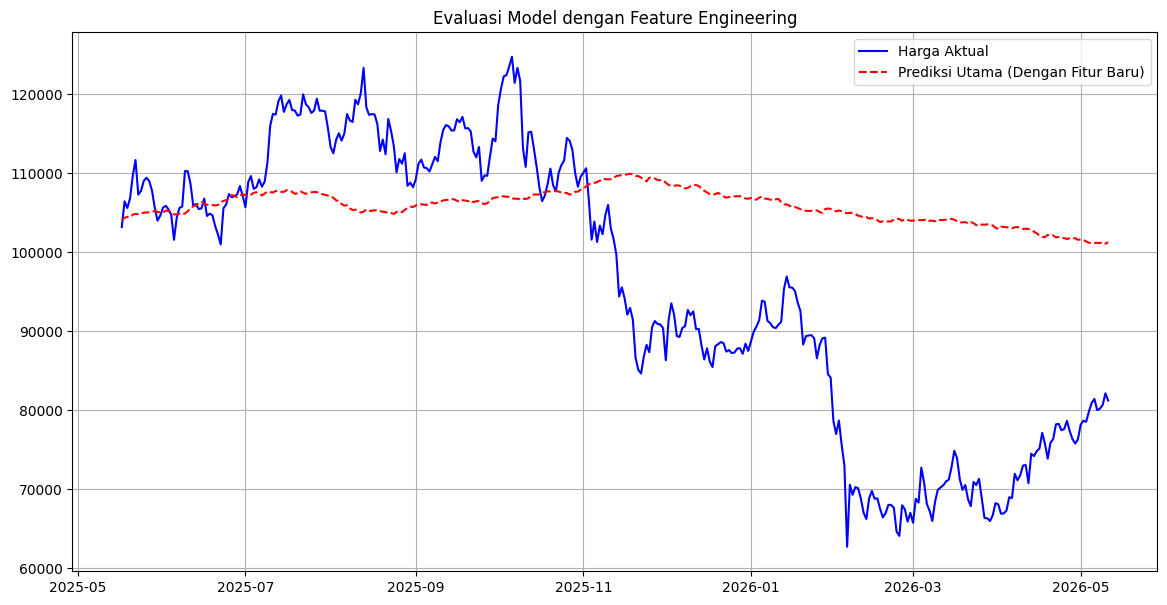

In [5]:
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import numpy as np
from autogluon.timeseries import TimeSeriesDataFrame, TimeSeriesPredictor
from sklearn.metrics import mean_absolute_percentage_error

# ---------------------------------------------------------
# 1. DOWNLOAD DATA & FEATURE ENGINEERING
# ---------------------------------------------------------
print("Mengunduh data historis BTC-USD 5 Tahun...")
btc_data = yf.download("BTC-USD", period="5y", interval="1d")

df = pd.DataFrame()
df['Date'] = pd.to_datetime(btc_data.index).tz_localize(None)

# Handle yfinance MultiIndex format
if isinstance(btc_data['Close'], pd.DataFrame):
    df['Close'] = btc_data['Close'].iloc[:, 0].astype(float).values
    df['Volume'] = btc_data['Volume'].iloc[:, 0].astype(float).values
else:
    df['Close'] = btc_data['Close'].astype(float).values
    df['Volume'] = btc_data['Volume'].astype(float).values

# --- MULAI FEATURE ENGINEERING ---
# 1. Moving Averages (Tren Jangka Pendek & Menengah)
df['SMA_7'] = df['Close'].rolling(window=7).mean()
df['SMA_30'] = df['Close'].rolling(window=30).mean()

# 2. Daily Return (Persentase keuntungan/kerugian harian)
df['Daily_Return'] = df['Close'].pct_change()

# 3. Volatility (Standar deviasi pergerakan 7 hari terakhir)
df['Volatility_7d'] = df['Daily_Return'].rolling(window=7).std()

# Hapus baris yang mengandung NaN (karena efek dari rolling/pct_change pada hari-hari awal)
df = df.dropna().reset_index(drop=True)
# --- SELESAI FEATURE ENGINEERING ---

df['Ticker'] = 'BTC'

# ---------------------------------------------------------
# 2. SPLIT DATA: 80% TRAIN & 20% TEST
# ---------------------------------------------------------
total_rows = len(df)
split_index = int(total_rows * 0.8)

train_df = df.iloc[:split_index].copy()
test_df = df.iloc[split_index:].copy()
prediction_len = len(test_df)

print(f"\nTotal Data setelah Feature Engineering: {total_rows} Hari")

# Saat kita mengonversi ke TimeSeriesDataFrame, AutoGluon otomatis membaca 
# kolom Volume, SMA, Return, dan Volatility sebagai "past_covariates"
train_data = TimeSeriesDataFrame.from_data_frame(
    train_df, id_column="Ticker", timestamp_column="Date"
)

# ---------------------------------------------------------
# 3. PELATIHAN MODEL (Ditingkatkan)
# ---------------------------------------------------------
print("\nMelatih model...")
predictor_eval = TimeSeriesPredictor(
    prediction_length=prediction_len, 
    target="Close", 
    eval_metric="MAPE", 
    freq="D",
    known_covariates_names=None # Fitur kita otomatis masuk sebagai past_covariates
)

# KITA TINGKATKAN PRESET DAN WAKTU TRAINING
# "high_quality" memaksa AutoGluon mencoba model Deep Learning yang lebih kompleks
predictor_eval.fit(
    train_data, 
    presets="high_quality", 
    time_limit=300 # Naikkan ke 5 menit (300 detik) agar model bisa belajar lebih dalam
)

predictions_eval = predictor_eval.predict(train_data)

# ---------------------------------------------------------
# 4. EVALUASI
# ---------------------------------------------------------
df_hasil_eval = predictions_eval.reset_index()
df_hasil_eval = df_hasil_eval[['item_id', 'timestamp', 'mean', '0.1', '0.9']].copy()
df_hasil_eval.columns = ['Aset', 'Tanggal', 'Prediksi_Utama', 'Skenario_Pesimis', 'Skenario_Optimis']

hasil_evaluasi = pd.merge(df_hasil_eval, test_df, left_on='Tanggal', right_on='Date')
hasil_evaluasi = hasil_evaluasi.rename(columns={'Close': 'Harga_Asli'})

mape = mean_absolute_percentage_error(hasil_evaluasi['Harga_Asli'], hasil_evaluasi['Prediksi_Utama'])
print(f"\nEstimasi Akurasi Prediksi: {100 - (mape * 100):.2f}%")

# Plot Evaluasi
plt.figure(figsize=(14, 7))
plt.plot(hasil_evaluasi['Tanggal'], hasil_evaluasi['Harga_Asli'], label='Harga Aktual', color='blue')
plt.plot(hasil_evaluasi['Tanggal'], hasil_evaluasi['Prediksi_Utama'], label='Prediksi Utama (Dengan Fitur Baru)', color='red', linestyle='dashed')
plt.title('Evaluasi Model dengan Feature Engineering')
plt.legend()
plt.grid(True)
plt.show()

Mengunduh dan memproses data BTC-USD...


[*********************100%***********************]  1 of 1 completed
No path specified. Models will be saved in: "AutogluonModels/ag-20260511_160228"
Beginning AutoGluon training... Time limit = 300s
AutoGluon will save models to '/Applications/MAMP/htdocs/local/kodingakademi/Python/python 4/bootcamp batch 3/final/AutogluonModels/ag-20260511_160228'
=================== System Info ===================
AutoGluon Version:  1.5.0
Python Version:     3.12.7
Operating System:   Darwin
Platform Machine:   arm64
Platform Version:   Darwin Kernel Version 25.2.0: Tue Nov 18 21:03:25 PST 2025; root:xnu-12377.61.12~1/RELEASE_ARM64_T8122
CPU Count:          8
Pytorch Version:    2.9.1
CUDA Version:       CUDA is not available
GPU Count:          WARNING: Exception was raised when calculating GPU count (AssertionError)
Memory Avail:       2.34 GB / 8.00 GB (29.2%)
Disk Space Avail:   11.86 GB / 228.27 GB (5.2%)
Setting presets to: high_quality

Fitting with arguments:
{'enable_ensemble': True,
 'eva


Total Data BTC-USD setelah Feature Engineering: 1808 Hari
Data Training: 1778 Hari
Data Testing : 30 Hari

Melatih model AutoGluon...


	-0.0317       = Validation score (-MAPE)
	1.27    s     = Training runtime
	0.03    s     = Validation (prediction) runtime
Training timeseries model DirectTabular. Training for up to 42.7s of the 298.7s of remaining time.
	-0.0478       = Validation score (-MAPE)
	1.13    s     = Training runtime
	0.02    s     = Validation (prediction) runtime
Training timeseries model Chronos2. Training for up to 49.6s of the 297.5s of remaining time.
	-0.0297       = Validation score (-MAPE)
	1.66    s     = Training runtime
	1.63    s     = Validation (prediction) runtime
Training timeseries model Chronos2SmallFineTuned. Training for up to 58.8s of the 294.2s of remaining time.
	-0.0328       = Validation score (-MAPE)
	56.68   s     = Training runtime
	0.45    s     = Validation (prediction) runtime
Training timeseries model ChronosWithRegressor[bolt_small]. Training for up to 59.3s of the 237.1s of remaining time.
	Skipping covariate_regressor since the dataset contains no known_covariates or s


--- HASIL EVALUASI BTC-USD ---
Estimasi Akurasi Prediksi: 93.48%


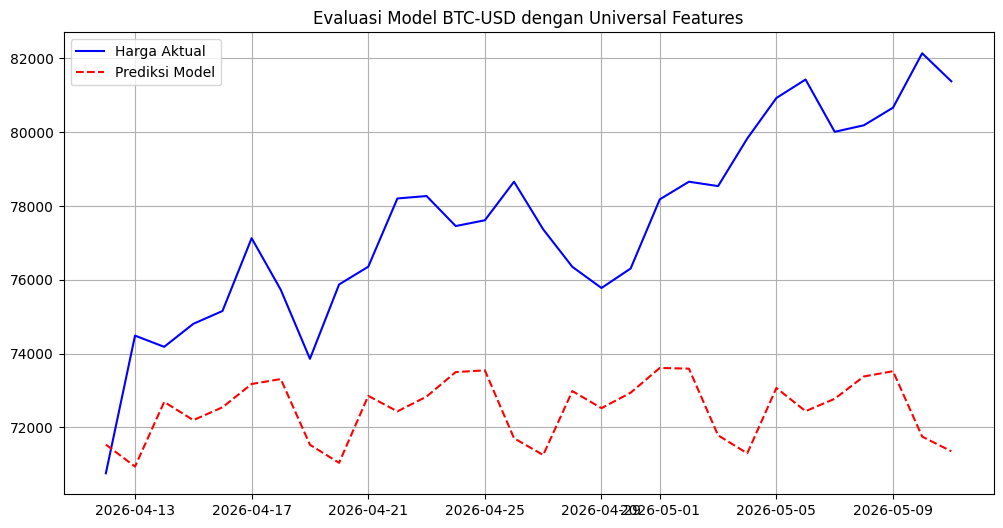

In [7]:
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from autogluon.timeseries import TimeSeriesDataFrame, TimeSeriesPredictor
from sklearn.metrics import mean_absolute_percentage_error

# ---------------------------------------------------------
# 1. FUNGSI FEATURE ENGINEERING UNIVERSAL
# ---------------------------------------------------------
def siapkan_data_crypto(ticker="BTC-USD", periode="5y"):
    print(f"Mengunduh dan memproses data {ticker}...")
    data = yf.download(ticker, period=periode, interval="1d")
    
    df = pd.DataFrame()
    df['Date'] = pd.to_datetime(data.index).tz_localize(None)
    
    # Handle format multi-index yfinance
    if isinstance(data['Close'], pd.DataFrame):
        df['Close'] = data['Close'].iloc[:, 0].astype(float).values
        df['Volume'] = data['Volume'].iloc[:, 0].astype(float).values
    else:
        df['Close'] = data['Close'].astype(float).values
        df['Volume'] = data['Volume'].astype(float).values
        
    df['Ticker'] = ticker.split('-')[0] # Ambil nama depannya saja (Contoh: "ETH")
    
    # --- MULAI FEATURE ENGINEERING ---
    
    # 1. Tren Dasar & Perubahan Harga
    df['SMA_14'] = df['Close'].rolling(window=14).mean()
    df['Daily_Return'] = df['Close'].pct_change()
    
    # 2. RSI (Relative Strength Index) - 14 Hari
    # Mengukur apakah koin sedang jenuh beli (overbought) atau jenuh jual (oversold)
    delta = df['Close'].diff()
    gain = (delta.where(delta > 0, 0)).rolling(window=14).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(window=14).mean()
    rs = gain / loss
    df['RSI_14'] = 100 - (100 / (1 + rs))
    
    # 3. MACD (Moving Average Convergence Divergence)
    # Sangat akurat untuk melihat perubahan arah tren awal di semua koin
    exp1 = df['Close'].ewm(span=12, adjust=False).mean()
    exp2 = df['Close'].ewm(span=26, adjust=False).mean()
    df['MACD'] = exp1 - exp2
    df['MACD_Signal'] = df['MACD'].ewm(span=9, adjust=False).mean()
    
    # 4. Volatilitas Universal (Bollinger Band Width)
    # Mengukur seberapa lebar/sempit volatilitas tanpa peduli harga koinnya murah/mahal
    df['BB_Middle'] = df['Close'].rolling(window=20).mean()
    std_20 = df['Close'].rolling(window=20).std()
    df['BB_Upper'] = df['BB_Middle'] + (2 * std_20)
    df['BB_Lower'] = df['BB_Middle'] - (2 * std_20)
    df['BB_Width'] = (df['BB_Upper'] - df['BB_Lower']) / df['BB_Middle'] 
    
    # 5. Ekstraksi Fitur Kalender (Waktu)
    # Membantu AutoGluon mengenali pola mingguan/bulanan (misal: weekend efek)
    df['Day_of_Week'] = df['Date'].dt.dayofweek
    df['Month'] = df['Date'].dt.month
    
    # Hapus baris NaN akibat perhitungan rolling/indikator di hari-hari pertama
    df = df.dropna().reset_index(drop=True)
    # --- SELESAI FEATURE ENGINEERING ---
    
    return df

# ---------------------------------------------------------
# 2. EKSEKUSI UNTUK KOIN APAPUN (CONTOH: ETHEREUM)
# ---------------------------------------------------------
ticker_target = "BTC-USD"  # Coba ganti dengan "SOL-USD", "ADA-USD", atau "BNB-USD"

df = siapkan_data_crypto(ticker=ticker_target)
print(f"\nTotal Data {ticker_target} setelah Feature Engineering: {len(df)} Hari")

# ---------------------------------------------------------
# 3. SPLIT DATA YANG LEBIH REALISTIS (PREDIKSI 30 HARI)
# ---------------------------------------------------------
prediction_len = 30 # Kita hanya akan memprediksi 30 hari terakhir untuk evaluasi

train_df = df.iloc[:-prediction_len].copy()
test_df = df.iloc[-prediction_len:].copy()

print(f"Data Training: {len(train_df)} Hari")
print(f"Data Testing : {len(test_df)} Hari")

train_data = TimeSeriesDataFrame.from_data_frame(
    train_df, id_column="Ticker", timestamp_column="Date"
)

# ---------------------------------------------------------
# 4. PELATIHAN MODEL (MEMAKSA DEEP LEARNING)
# ---------------------------------------------------------
print("\nMelatih model AutoGluon...")
predictor = TimeSeriesPredictor(
    prediction_length=prediction_len, 
    target="Close", 
    eval_metric="MAPE", 
    freq="D"
)

# Kita 'banned' model statistik klasik agar AutoGluon fokus ke model canggih
# yang menggunakan past_covariates (fitur RSI, MACD, dll)
model_klasik = ['AutoETS', 'SeasonalNaive', 'DynamicOptimizedTheta', 'ARIMA']

predictor.fit(
    train_data, 
    presets="high_quality", 
    time_limit=300,
    excluded_model_types=model_klasik  # <--- Tambahan ini sangat penting
)

# Prediksi
predictions = predictor.predict(train_data)

# ---------------------------------------------------------
# 5. EVALUASI
# ---------------------------------------------------------
df_hasil = predictions.reset_index()
df_hasil = df_hasil[['item_id', 'timestamp', 'mean']].copy()
df_hasil.columns = ['Aset', 'Tanggal', 'Prediksi_Utama']

hasil_evaluasi = pd.merge(df_hasil, test_df, left_on='Tanggal', right_on='Date')
hasil_evaluasi = hasil_evaluasi.rename(columns={'Close': 'Harga_Asli'})

mape = mean_absolute_percentage_error(hasil_evaluasi['Harga_Asli'], hasil_evaluasi['Prediksi_Utama'])
print(f"\n--- HASIL EVALUASI {ticker_target} ---")
print(f"Estimasi Akurasi Prediksi: {100 - (mape * 100):.2f}%")

# Visualisasi Cepat
plt.figure(figsize=(12, 6))
plt.plot(hasil_evaluasi['Tanggal'], hasil_evaluasi['Harga_Asli'], label='Harga Aktual', color='blue')
plt.plot(hasil_evaluasi['Tanggal'], hasil_evaluasi['Prediksi_Utama'], label='Prediksi Model', color='red', linestyle='dashed')
plt.title(f'Evaluasi Model {ticker_target} dengan Universal Features')
plt.legend()
plt.grid(True)
plt.show()

Mengunduh dan memproses data BTC-USD...


[*********************100%***********************]  1 of 1 completed
No path specified. Models will be saved in: "AutogluonModels/ag-20260511_161344"
Beginning AutoGluon training... Time limit = 300s
AutoGluon will save models to '/Applications/MAMP/htdocs/local/kodingakademi/Python/python 4/bootcamp batch 3/final/AutogluonModels/ag-20260511_161344'
=================== System Info ===================
AutoGluon Version:  1.5.0
Python Version:     3.12.7
Operating System:   Darwin
Platform Machine:   arm64
Platform Version:   Darwin Kernel Version 25.2.0: Tue Nov 18 21:03:25 PST 2025; root:xnu-12377.61.12~1/RELEASE_ARM64_T8122
CPU Count:          8
Pytorch Version:    2.9.1
CUDA Version:       CUDA is not available
GPU Count:          WARNING: Exception was raised when calculating GPU count (AssertionError)
Memory Avail:       1.90 GB / 8.00 GB (23.8%)
Disk Space Avail:   11.88 GB / 228.27 GB (5.2%)
Setting presets to: high_quality

Fitting with arguments:
{'enable_ensemble': True,
 'eva


--- SKENARIO BACKTESTING ---
Total Data      : 1808 Hari
Data Pelatihan  : 1658 Hari (Awal hingga T-150)
Total Ujian     : 5 Jendela (Total 150 Hari)

Melatih Model Inti...


	-0.0706       = Validation score (-MAPE)
	1.40    s     = Training runtime
	0.03    s     = Validation (prediction) runtime
Training timeseries model DirectTabular. Training for up to 42.6s of the 298.5s of remaining time.
	-0.1927       = Validation score (-MAPE)
	1.26    s     = Training runtime
	0.02    s     = Validation (prediction) runtime
Training timeseries model Chronos2. Training for up to 49.5s of the 297.3s of remaining time.
	-0.1246       = Validation score (-MAPE)
	1.43    s     = Training runtime
	1.64    s     = Validation (prediction) runtime
Training timeseries model Chronos2SmallFineTuned. Training for up to 58.8s of the 294.2s of remaining time.
	-0.1330       = Validation score (-MAPE)
	55.90   s     = Training runtime
	0.45    s     = Validation (prediction) runtime
Training timeseries model ChronosWithRegressor[bolt_small]. Training for up to 59.5s of the 237.8s of remaining time.
	Skipping covariate_regressor since the dataset contains no known_covariates or s


Memulai Simulasi Backtesting Berjalan...
-> Simulasi Window 1/5 | Memprediksi 30 Hari Mulai 2025-12-12...
-> Simulasi Window 2/5 | Memprediksi 30 Hari Mulai 2026-01-11...
-> Simulasi Window 3/5 | Memprediksi 30 Hari Mulai 2026-02-10...


Model not specified in predict, will default to the model with the best validation score: WeightedEnsemble
Model not specified in predict, will default to the model with the best validation score: WeightedEnsemble


-> Simulasi Window 4/5 | Memprediksi 30 Hari Mulai 2026-03-12...
-> Simulasi Window 5/5 | Memprediksi 30 Hari Mulai 2026-04-11...

--- HASIL AKHIR BACKTESTING 5 BULAN ---
Rata-rata Akurasi Keseluruhan: 92.28%


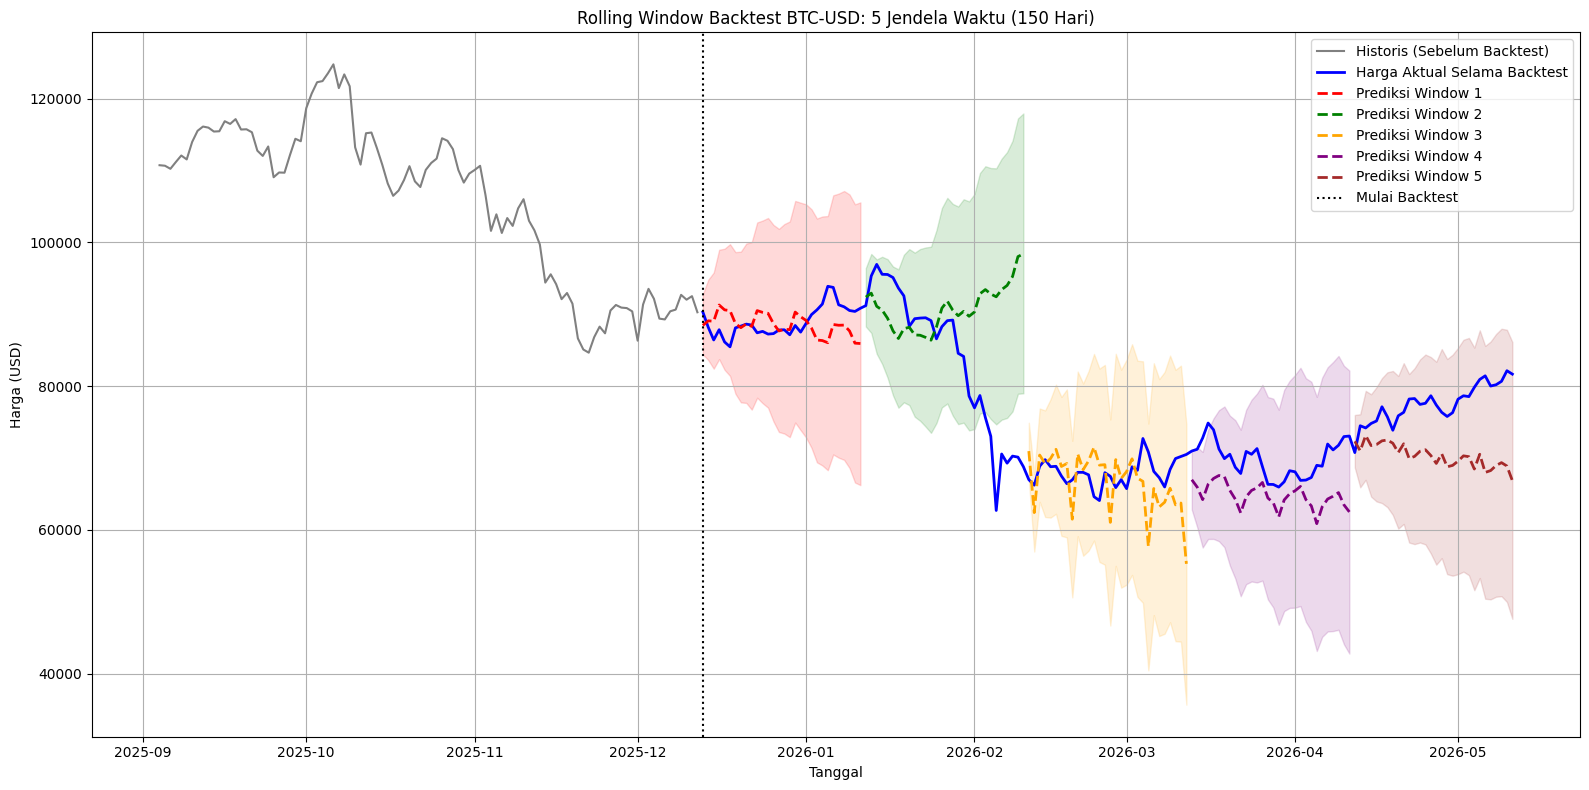

In [8]:
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from autogluon.timeseries import TimeSeriesDataFrame, TimeSeriesPredictor
from sklearn.metrics import mean_absolute_percentage_error

# ---------------------------------------------------------
# 1. FUNGSI FEATURE ENGINEERING UNIVERSAL
# ---------------------------------------------------------
def siapkan_data_crypto(ticker="BTC-USD", periode="5y"):
    print(f"Mengunduh dan memproses data {ticker}...")
    data = yf.download(ticker, period=periode, interval="1d")
    
    df = pd.DataFrame()
    df['Date'] = pd.to_datetime(data.index).tz_localize(None)
    
    if isinstance(data['Close'], pd.DataFrame):
        df['Close'] = data['Close'].iloc[:, 0].astype(float).values
        df['Volume'] = data['Volume'].iloc[:, 0].astype(float).values
    else:
        df['Close'] = data['Close'].astype(float).values
        df['Volume'] = data['Volume'].astype(float).values
        
    df['Ticker'] = ticker.split('-')[0] 
    
    # Fitur Teknikal Universal
    df['SMA_14'] = df['Close'].rolling(window=14).mean()
    df['Daily_Return'] = df['Close'].pct_change()
    
    delta = df['Close'].diff()
    gain = (delta.where(delta > 0, 0)).rolling(window=14).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(window=14).mean()
    rs = gain / loss
    df['RSI_14'] = 100 - (100 / (1 + rs))
    
    exp1 = df['Close'].ewm(span=12, adjust=False).mean()
    exp2 = df['Close'].ewm(span=26, adjust=False).mean()
    df['MACD'] = exp1 - exp2
    df['MACD_Signal'] = df['MACD'].ewm(span=9, adjust=False).mean()
    
    df['BB_Middle'] = df['Close'].rolling(window=20).mean()
    std_20 = df['Close'].rolling(window=20).std()
    df['BB_Upper'] = df['BB_Middle'] + (2 * std_20)
    df['BB_Lower'] = df['BB_Middle'] - (2 * std_20)
    df['BB_Width'] = (df['BB_Upper'] - df['BB_Lower']) / df['BB_Middle'] 
    
    # Fitur Kalender
    df['Day_of_Week'] = df['Date'].dt.dayofweek
    df['Month'] = df['Date'].dt.month
    
    df = df.dropna().reset_index(drop=True)
    return df

# ---------------------------------------------------------
# 2. KONFIGURASI BACKTESTING
# ---------------------------------------------------------
ticker_target = "BTC-USD"
df = siapkan_data_crypto(ticker=ticker_target)

pred_length = 30      # Memprediksi 30 hari ke depan per iterasi
num_windows = 5       # Lakukan pengujian untuk 5 bulan terakhir (5 x 30 hari = 150 hari)

# Menghitung batas pemotongan data
total_rows = len(df)
test_size = pred_length * num_windows
train_size = total_rows - test_size

print(f"\n--- SKENARIO BACKTESTING ---")
print(f"Total Data      : {total_rows} Hari")
print(f"Data Pelatihan  : {train_size} Hari (Awal hingga T-{test_size})")
print(f"Total Ujian     : {num_windows} Jendela (Total {test_size} Hari)")

# Pisahkan data untuk pelatihan awal
train_df = df.iloc[:train_size].copy()

# Konversi ke format AutoGluon
train_data = TimeSeriesDataFrame.from_data_frame(
    train_df, id_column="Ticker", timestamp_column="Date"
)

# ---------------------------------------------------------
# 3. PELATIHAN MODEL (HANYA SATU KALI)
# ---------------------------------------------------------
print("\nMelatih Model Inti...")
predictor = TimeSeriesPredictor(
    prediction_length=pred_length, 
    target="Close", 
    eval_metric="MAPE", 
    freq="D"
)

model_klasik = ['AutoETS', 'SeasonalNaive', 'DynamicOptimizedTheta', 'ARIMA']

predictor.fit(
    train_data, 
    presets="high_quality", 
    time_limit=300, 
    excluded_model_types=model_klasik
)

# ---------------------------------------------------------
# 4. ROLLING WINDOW LOOP (SIMULASI MASA DEPAN)
# ---------------------------------------------------------
print("\nMemulai Simulasi Backtesting Berjalan...")
semua_prediksi = []

for i in range(num_windows):
    # Hitung batas data untuk jendela saat ini
    # Di iterasi ke-0, kita menggunakan data pelatihan asli.
    # Di iterasi berikutnya, kita menambahkan 30 hari data aktual sebagai "konteks" baru.
    batas_konteks = train_size + (i * pred_length)
    
    # Ambil data dari awal hingga batas konteks saat ini
    konteks_df = df.iloc[:batas_konteks].copy()
    
    # Ubah ke format AutoGluon
    konteks_data = TimeSeriesDataFrame.from_data_frame(
        konteks_df, id_column="Ticker", timestamp_column="Date"
    )
    
    print(f"-> Simulasi Window {i+1}/{num_windows} | Memprediksi 30 Hari Mulai {konteks_df['Date'].iloc[-1].strftime('%Y-%m-%d')}...")
    
    # Prediksi 30 hari ke depan berdasarkan konteks terbaru (tanpa melatih ulang model)
    pred_jendela = predictor.predict(konteks_data)
    
    # Rapikan hasil prediksi
    pred_df = pred_jendela.reset_index()
    pred_df = pred_df[['item_id', 'timestamp', 'mean', '0.1', '0.9']].copy()
    pred_df.columns = ['Aset', 'Tanggal', 'Prediksi_Utama', 'Skenario_Pesimis', 'Skenario_Optimis']
    pred_df['Window_ID'] = i + 1
    
    # Simpan hasil
    semua_prediksi.append(pred_df)

# Gabungkan seluruh hasil prediksi dari semua jendela menjadi satu tabel
df_hasil_backtest = pd.concat(semua_prediksi, ignore_index=True)

# ---------------------------------------------------------
# 5. EVALUASI DAN VISUALISASI KESELURUHAN
# ---------------------------------------------------------
# Gabungkan dengan harga asli untuk dibandingkan
hasil_akhir = pd.merge(df_hasil_backtest, df[['Date', 'Close']], left_on='Tanggal', right_on='Date', how='inner')
hasil_akhir = hasil_akhir.rename(columns={'Close': 'Harga_Asli'})

# Hitung Akurasi Total
mape_total = mean_absolute_percentage_error(hasil_akhir['Harga_Asli'], hasil_akhir['Prediksi_Utama'])
akurasi_total = 100 - (mape_total * 100)

print(f"\n--- HASIL AKHIR BACKTESTING {num_windows} BULAN ---")
print(f"Rata-rata Akurasi Keseluruhan: {akurasi_total:.2f}%")

# Visualisasi
plt.figure(figsize=(16, 8))

# Tampilkan data historis sebelumnya sebagai konteks visual (100 hari sebelum backtest dimulai)
data_historis_visual = df.iloc[train_size-100 : train_size]
plt.plot(data_historis_visual['Date'], data_historis_visual['Close'], label='Historis (Sebelum Backtest)', color='gray')

# Tampilkan harga asli selama periode backtest
plt.plot(hasil_akhir['Tanggal'], hasil_akhir['Harga_Asli'], label='Harga Aktual Selama Backtest', color='blue', linewidth=2)

# Gunakan warna yang berbeda untuk membedakan tiap window prediksi
colors = ['red', 'green', 'orange', 'purple', 'brown']

for i in range(num_windows):
    window_data = hasil_akhir[hasil_akhir['Window_ID'] == (i + 1)]
    warna = colors[i % len(colors)]
    
    plt.plot(window_data['Tanggal'], window_data['Prediksi_Utama'], 
             label=f'Prediksi Window {i+1}', color=warna, linestyle='dashed', linewidth=2)
    
    plt.fill_between(window_data['Tanggal'], window_data['Skenario_Pesimis'], window_data['Skenario_Optimis'], 
                     color=warna, alpha=0.15)

# Menambahkan garis vertikal sebagai penanda mulai backtest
plt.axvline(x=hasil_akhir['Tanggal'].iloc[0], color='black', linestyle='dotted', label='Mulai Backtest')

plt.title(f'Rolling Window Backtest {ticker_target}: {num_windows} Jendela Waktu (150 Hari)')
plt.xlabel('Tanggal')
plt.ylabel('Harga (USD)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Mengunduh data historis BTC-USD...


[*********************100%***********************]  1 of 1 completed
No path specified. Models will be saved in: "AutogluonModels/ag-20260511_162312"
Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.5.0
Python Version:     3.12.7
Operating System:   Darwin
Platform Machine:   arm64
Platform Version:   Darwin Kernel Version 25.2.0: Tue Nov 18 21:03:25 PST 2025; root:xnu-12377.61.12~1/RELEASE_ARM64_T8122
CPU Count:          8
Pytorch Version:    2.9.1
CUDA Version:       CUDA is not available
GPU Count:          WARNING: Exception was raised when calculating GPU count (AssertionError)
Memory Avail:       1.79 GB / 8.00 GB (22.4%)
Disk Space Avail:   11.87 GB / 228.27 GB (5.2%)
Presets specified: ['best_quality']
Using hyperparameters preset: hyperparameters='zeroshot'
Setting dynamic_stacking from 'auto' to True. Reason: Enable dynamic_stacking when use_bag_holdout is disabled. (use_bag_holdout=False)
Stack configuration (auto_stac


--- INFORMASI DATA ---
Data Pelatihan (Masa Lalu): 1448 Hari
Data Simulasi Ujian (1 Tahun Terakhir): 365 Hari

Melatih Model Machine Learning untuk Mencari Sinyal Buy/Sell...


Beginning AutoGluon training ... Time limit = 45s
AutoGluon will save models to "/Applications/MAMP/htdocs/local/kodingakademi/Python/python 4/bootcamp batch 3/final/AutogluonModels/ag-20260511_162312/ds_sub_fit/sub_fit_ho"
Train Data Rows:    1287
Train Data Columns: 12
Label Column:       Target_Direction
Problem Type:       binary
Preprocessing data ...
Selected class <--> label mapping:  class 1 = 1, class 0 = 0
Using Feature Generators to preprocess the data ...
Fitting AutoMLPipelineFeatureGenerator...
	Available Memory:                    1846.49 MB
	Train Data (Original)  Memory Usage: 0.11 MB (0.0% of available memory)
	Inferring data type of each feature based on column values. Set feature_metadata_in to manually specify special dtypes of the features.
	Stage 1 Generators:
		Fitting AsTypeFeatureGenerator...
	Stage 2 Generators:
		Fitting FillNaFeatureGenerator...
	Stage 3 Generators:
		Fitting IdentityFeatureGenerator...
	Stage 4 Generators:
		Fitting DropUniqueFeatureGenera


--- LAPORAN KLASIFIKASI (1 TAHUN TERAKHIR) ---
                    precision    recall  f1-score   support

Prediksi TURUN (0)       0.45      0.50      0.48       183
 Prediksi NAIK (1)       0.44      0.39      0.41       182

          accuracy                           0.45       365
         macro avg       0.45      0.45      0.44       365
      weighted avg       0.45      0.45      0.44       365


--- HASIL SIMULASI UANG NYATA ---
Keuntungan Strategi Buy & Hold : -21.42%
Keuntungan Strategi Sinyal ML  : -40.62%


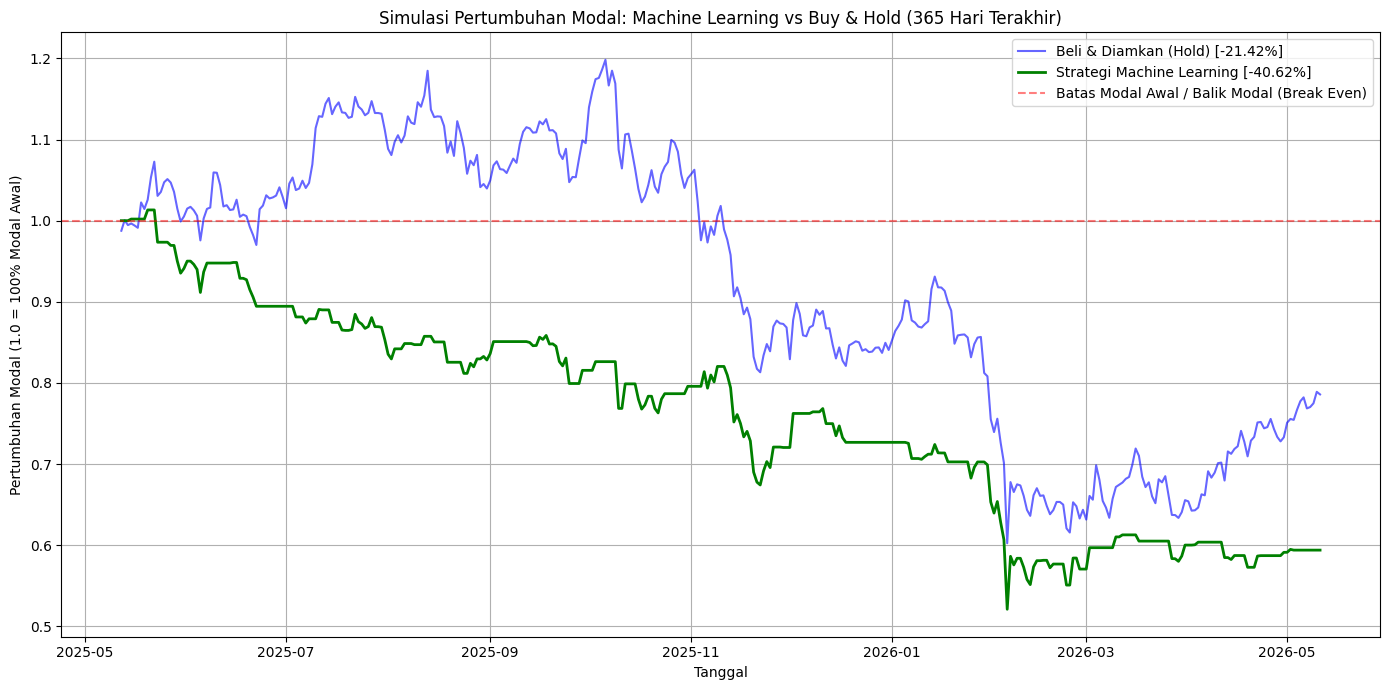

In [9]:
import pandas as pd
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt
from autogluon.tabular import TabularDataset, TabularPredictor
from sklearn.metrics import classification_report, accuracy_score

# ---------------------------------------------------------
# 1. DOWNLOAD DATA & FEATURE ENGINEERING
# ---------------------------------------------------------
print("Mengunduh data historis BTC-USD...")
data = yf.download("BTC-USD", period="5y", interval="1d")

df = pd.DataFrame()
df['Date'] = pd.to_datetime(data.index).tz_localize(None)

if isinstance(data['Close'], pd.DataFrame):
    df['Close'] = data['Close'].iloc[:, 0].astype(float).values
    df['Volume'] = data['Volume'].iloc[:, 0].astype(float).values
else:
    df['Close'] = data['Close'].astype(float).values
    df['Volume'] = data['Volume'].astype(float).values

# --- Fitur Momentum & Volatilitas (Input X) ---
df['Daily_Return'] = df['Close'].pct_change()
df['Lag_Return_1d'] = df['Daily_Return'].shift(1) # Return kemarin
df['Lag_Return_2d'] = df['Daily_Return'].shift(2) # Return lusa
df['Lag_Return_3d'] = df['Daily_Return'].shift(3) 

df['SMA_14_Ratio'] = df['Close'] / df['Close'].rolling(window=14).mean() # Rasio harga terhadap rata-rata
df['Volatility_14d'] = df['Daily_Return'].rolling(window=14).std()

# RSI 14
delta = df['Close'].diff()
gain = (delta.where(delta > 0, 0)).rolling(window=14).mean()
loss = (-delta.where(delta < 0, 0)).rolling(window=14).mean()
rs = gain / loss
df['RSI_14'] = 100 - (100 / (1 + rs))

# MACD
exp1 = df['Close'].ewm(span=12, adjust=False).mean()
exp2 = df['Close'].ewm(span=26, adjust=False).mean()
df['MACD'] = exp1 - exp2
df['MACD_Signal'] = df['MACD'].ewm(span=9, adjust=False).mean()
df['MACD_Hist'] = df['MACD'] - df['MACD_Signal'] # Jarak antara MACD dan Signal

# Ekstraksi Kalender
df['Day_of_Week'] = df['Date'].dt.dayofweek

# --- TARGET KLASIFIKASI (Label y) ---
# Apakah harga penutupan BESOK lebih tinggi dari HARI INI? (1 = Naik/Beli, 0 = Turun/Hindari)
df['Target_Direction'] = (df['Close'].shift(-1) > df['Close']).astype(int)

# Hapus NaN (akibat indikator rolling dan shift) dan baris terakhir yang targetnya belum diketahui
df = df.dropna()

# ---------------------------------------------------------
# 2. SPLIT DATA WAKTU (Simulasi Trading 1 Tahun Terakhir)
# ---------------------------------------------------------
# Kita sisihkan 365 hari terakhir secara mutlak sebagai data ujian (Out-of-Sample)
test_days = 365
train_df = df.iloc[:-test_days].copy()
test_df = df.iloc[-test_days:].copy()

print(f"\n--- INFORMASI DATA ---")
print(f"Data Pelatihan (Masa Lalu): {len(train_df)} Hari")
print(f"Data Simulasi Ujian (1 Tahun Terakhir): {len(test_df)} Hari")

# PENTING: Kita harus membuang kolom harga nominal dan tanggal agar mesin 
# tidak Overfitting dan murni belajar dari indikator persentase.
kolom_dibuang = ['Date', 'Close'] 

train_data = TabularDataset(train_df.drop(columns=kolom_dibuang))
test_data = TabularDataset(test_df.drop(columns=kolom_dibuang))

# ---------------------------------------------------------
# 3. PELATIHAN MODEL AUTOGLUON TABULAR
# ---------------------------------------------------------
print("\nMelatih Model Machine Learning untuk Mencari Sinyal Buy/Sell...")
# Menggunakan TabularPredictor, bukan TimeSeriesPredictor
predictor = TabularPredictor(
    label='Target_Direction', 
    eval_metric='accuracy' # Fokus pada seberapa sering tebakannya benar
).fit(
    train_data, 
    presets='best_quality', # Gunakan algoritma terbaik (XGBoost, LightGBM, dll)
    time_limit=180
)

# ---------------------------------------------------------
# 4. PREDIKSI DAN EVALUASI MATRIKS (Berapa Akurasinya?)
# ---------------------------------------------------------
predictions = predictor.predict(test_data)
test_df['Sinyal_Model'] = predictions.values

print("\n--- LAPORAN KLASIFIKASI (1 TAHUN TERAKHIR) ---")
print(classification_report(test_df['Target_Direction'], test_df['Sinyal_Model'], target_names=['Prediksi TURUN (0)', 'Prediksi NAIK (1)']))

# ---------------------------------------------------------
# 5. SIMULASI STRATEGI TRADING (QUANT BACKTESTING)
# ---------------------------------------------------------
# Jika sinyal = 1 (Beli), kita dapat return BTC hari ITU. 
# Jika sinyal = 0 (Jual/Tunggu), return kita 0 (pegang tunai).
# Catatan: Kita menggeser Daily_Return karena sinyal hari ini digunakan untuk menangkap pergerakan besok.
test_df['Strategi_Mesin_Return'] = test_df['Sinyal_Model'].shift(1) * test_df['Daily_Return']
test_df['Buy_Hold_Return'] = test_df['Daily_Return']

# Isi baris pertama yang kosong dengan 0
test_df['Strategi_Mesin_Return'] = test_df['Strategi_Mesin_Return'].fillna(0)

# Hitung akumulasi keuntungan modal
# Asumsi modal awal adalah $1 (atau 100%)
test_df['Modal_Strategi_Mesin'] = (1 + test_df['Strategi_Mesin_Return']).cumprod()
test_df['Modal_Buy_Hold'] = (1 + test_df['Buy_Hold_Return']).cumprod()

untung_mesin = (test_df['Modal_Strategi_Mesin'].iloc[-1] - 1) * 100
untung_hold = (test_df['Modal_Buy_Hold'].iloc[-1] - 1) * 100

print("\n--- HASIL SIMULASI UANG NYATA ---")
print(f"Keuntungan Strategi Buy & Hold : {untung_hold:.2f}%")
print(f"Keuntungan Strategi Sinyal ML  : {untung_mesin:.2f}%")

# ---------------------------------------------------------
# 6. VISUALISASI PERTUMBUHAN MODAL
# ---------------------------------------------------------
plt.figure(figsize=(14, 7))
plt.plot(test_df['Date'], test_df['Modal_Buy_Hold'], label=f'Beli & Diamkan (Hold) [{untung_hold:.2f}%]', color='blue', alpha=0.6)
plt.plot(test_df['Date'], test_df['Modal_Strategi_Mesin'], label=f'Strategi Machine Learning [{untung_mesin:.2f}%]', color='green', linewidth=2)

# Tambahkan garis horizontal penanda modal awal (1.0)
plt.axhline(y=1.0, color='red', linestyle='--', alpha=0.5, label='Batas Modal Awal / Balik Modal (Break Even)')

plt.title('Simulasi Pertumbuhan Modal: Machine Learning vs Buy & Hold (365 Hari Terakhir)')
plt.xlabel('Tanggal')
plt.ylabel('Pertumbuhan Modal (1.0 = 100% Modal Awal)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Mengunduh data ETH-USD...


[*********************100%***********************]  1 of 1 completed
No path specified. Models will be saved in: "AutogluonModels/ag-20260511_163605"
Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.5.0
Python Version:     3.12.7
Operating System:   Darwin
Platform Machine:   arm64
Platform Version:   Darwin Kernel Version 25.2.0: Tue Nov 18 21:03:25 PST 2025; root:xnu-12377.61.12~1/RELEASE_ARM64_T8122
CPU Count:          8
Pytorch Version:    2.9.1
CUDA Version:       CUDA is not available
GPU Count:          WARNING: Exception was raised when calculating GPU count (AssertionError)
Memory Avail:       1.95 GB / 8.00 GB (24.4%)
Disk Space Avail:   11.61 GB / 228.27 GB (5.1%)
Presets specified: ['best_quality']
Using hyperparameters preset: hyperparameters='zeroshot'
Setting dynamic_stacking from 'auto' to True. Reason: Enable dynamic_stacking when use_bag_holdout is disabled. (use_bag_holdout=False)
Stack configuration (auto_stac

Merombak data ke timeframe Mingguan (Weekly)...

Melatih Model dengan Timeframe Mingguan...


Beginning AutoGluon training ... Time limit = 30s
AutoGluon will save models to "/Applications/MAMP/htdocs/local/kodingakademi/Python/python 4/bootcamp batch 3/final/AutogluonModels/ag-20260511_163605/ds_sub_fit/sub_fit_ho"
Train Data Rows:    175
Train Data Columns: 5
Label Column:       Target
Problem Type:       binary
Preprocessing data ...
Selected class <--> label mapping:  class 1 = 1, class 0 = 0
Using Feature Generators to preprocess the data ...
Fitting AutoMLPipelineFeatureGenerator...
	Available Memory:                    1999.60 MB
	Train Data (Original)  Memory Usage: 0.01 MB (0.0% of available memory)
	Inferring data type of each feature based on column values. Set feature_metadata_in to manually specify special dtypes of the features.
	Stage 1 Generators:
		Fitting AsTypeFeatureGenerator...
	Stage 2 Generators:
		Fitting FillNaFeatureGenerator...
	Stage 3 Generators:
		Fitting IdentityFeatureGenerator...
	Stage 4 Generators:
		Fitting DropUniqueFeatureGenerator...
	Stag


--- HASIL DENGAN FILTER PROBABILITAS 60.0% ---
Total Trade yang Dieksekusi: 10 kali dari 52 minggu
Profit AI Strategi : 68.85%
Profit Buy & Hold  : -6.51%


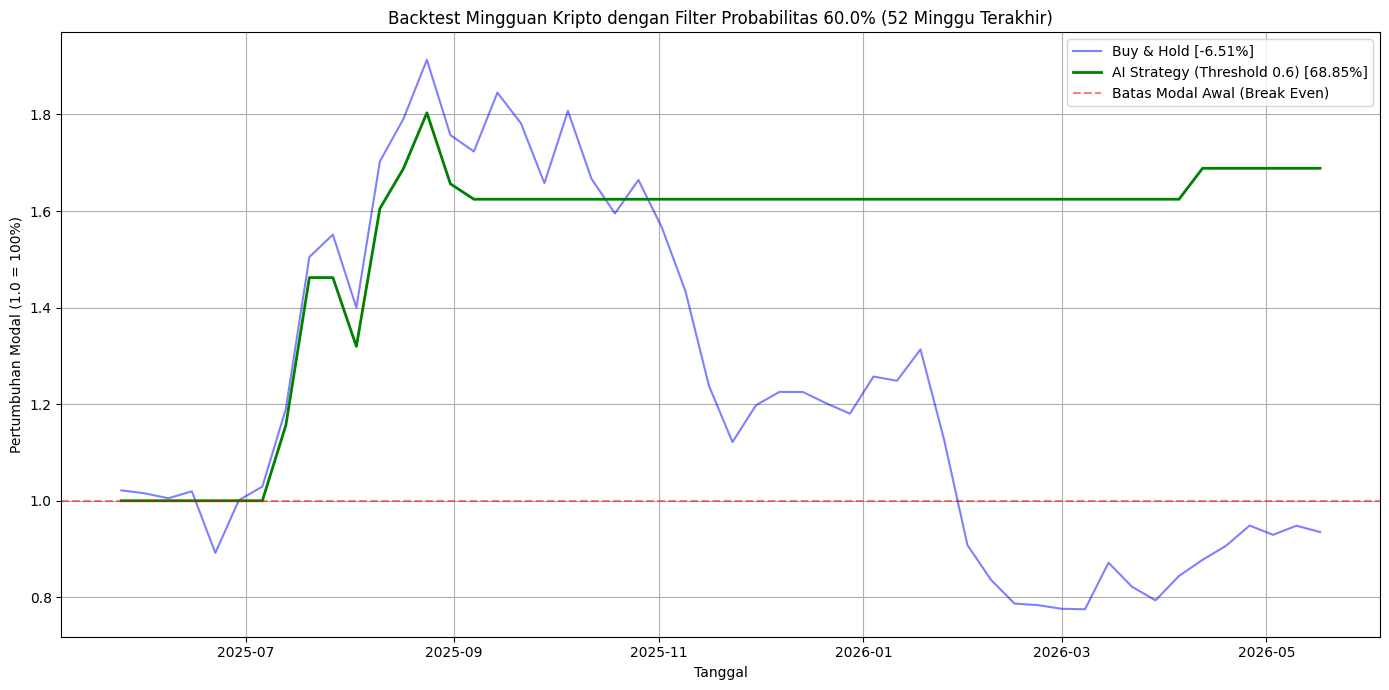

In [12]:
import pandas as pd
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt
from autogluon.tabular import TabularDataset, TabularPredictor

# ---------------------------------------------------------
# 1. DOWNLOAD & PREPROCESSING (Mengatasi MultiIndex yfinance)
# ---------------------------------------------------------
print("Mengunduh data ETH-USD...")
data = yf.download("ETH-USD", period="5y", interval="1d")

# Ekstrak data mentah dengan aman untuk menghindari MultiIndex
df_raw = pd.DataFrame()
df_raw['Date'] = pd.to_datetime(data.index).tz_localize(None)

if isinstance(data['Close'], pd.DataFrame):
    df_raw['Close'] = data['Close'].iloc[:, 0].astype(float).values
    df_raw['Volume'] = data['Volume'].iloc[:, 0].astype(float).values
else:
    df_raw['Close'] = data['Close'].astype(float).values
    df_raw['Volume'] = data['Volume'].astype(float).values

# Set index kembali ke tanggal untuk keperluan resample waktu
df_raw = df_raw.set_index('Date')

# ---------------------------------------------------------
# 2. RESAMPLE KE MINGGUAN (WEEKLY)
# ---------------------------------------------------------
print("Merombak data ke timeframe Mingguan (Weekly)...")
df_weekly = pd.DataFrame()

# Ambil harga penutupan terakhir di minggu tersebut
df_weekly['Close'] = df_raw['Close'].resample('W').last()
# Jumlahkan volume selama 1 minggu
df_weekly['Volume'] = df_raw['Volume'].resample('W').sum()

# --- Feature Engineering pada Data Mingguan ---
df_weekly['Weekly_Return'] = df_weekly['Close'].pct_change()

# RSI 14 Mingguan
delta = df_weekly['Close'].diff()
gain = (delta.where(delta > 0, 0)).rolling(window=14).mean()
loss = (-delta.where(delta < 0, 0)).rolling(window=14).mean()
rs = gain / loss
df_weekly['RSI_14'] = 100 - (100 / (1 + rs))

# MACD Mingguan
exp1 = df_weekly['Close'].ewm(span=12, adjust=False).mean()
exp2 = df_weekly['Close'].ewm(span=26, adjust=False).mean()
df_weekly['MACD_Hist'] = exp1 - exp2

# Volatilitas Mingguan (Standar deviasi 4 minggu terakhir = ~1 bulan)
df_weekly['Volatility_4w'] = df_weekly['Weekly_Return'].rolling(window=4).std()

# TARGET KLASIFIKASI: Apakah minggu depan harga ditutup lebih tinggi dari minggu ini?
df_weekly['Target'] = (df_weekly['Close'].shift(-1) > df_weekly['Close']).astype(int)

# Hapus baris NaN
df_weekly = df_weekly.dropna()

# ---------------------------------------------------------
# 3. SPLIT DATA & PELATIHAN MODEL
# ---------------------------------------------------------
# Ujian menggunakan 52 minggu terakhir (1 Tahun)
test_weeks = 52
train_df = df_weekly.iloc[:-test_weeks].copy()
test_df = df_weekly.iloc[-test_weeks:].copy()

# Buang kolom 'Close' absolut agar model murni menggunakan indikator & persentase
train_data = TabularDataset(train_df.drop(columns=['Close']))
test_data = TabularDataset(test_df.drop(columns=['Close']))

print("\nMelatih Model dengan Timeframe Mingguan...")
predictor = TabularPredictor(label='Target', eval_metric='accuracy').fit(
    train_data, presets='best_quality', time_limit=120
)

# ---------------------------------------------------------
# 4. PENERAPAN FILTER PROBABILITAS (THRESHOLD)
# ---------------------------------------------------------
# Ambil nilai probabilitas untuk tebakan kelas 1 (Prediksi Naik)
probabilities = predictor.predict_proba(test_data.drop(columns=['Target']))[1]

# FILTER PROBABILITAS: Robot hanya akan mengeksekusi BUY jika keyakinannya >= 60%
# Anda bisa menaikkan angka ini menjadi 0.70 (70%) untuk membuat bot lebih selektif/konservatif
THRESHOLD = 0.60 
test_df['Sinyal_Bot'] = (probabilities >= THRESHOLD).astype(int)

# ---------------------------------------------------------
# 5. BACKTESTING STRATEGI MINGGUAN
# ---------------------------------------------------------
# Jika sinyal minggu ini 1, kita menumpang return pada minggu depan
test_df['Return_Strategi'] = test_df['Sinyal_Bot'].shift(1) * test_df['Weekly_Return']
test_df['Return_Strategi'] = test_df['Return_Strategi'].fillna(0)

# Hitung Pertumbuhan Modal Akumulatif (Modal Awal = 1.0)
test_df['Modal_Strategi'] = (1 + test_df['Return_Strategi']).cumprod()
test_df['Modal_Hold'] = (1 + test_df['Weekly_Return'].fillna(0)).cumprod()

profit_strategi = (test_df['Modal_Strategi'].iloc[-1] - 1) * 100
profit_hold = (test_df['Modal_Hold'].iloc[-1] - 1) * 100

print(f"\n--- HASIL DENGAN FILTER PROBABILITAS {THRESHOLD*100}% ---")
print(f"Total Trade yang Dieksekusi: {test_df['Sinyal_Bot'].sum()} kali dari {test_weeks} minggu")
print(f"Profit AI Strategi : {profit_strategi:.2f}%")
print(f"Profit Buy & Hold  : {profit_hold:.2f}%")

# ---------------------------------------------------------
# 6. VISUALISASI PERTUMBUHAN MODAL
# ---------------------------------------------------------
plt.figure(figsize=(14, 7))
plt.plot(test_df.index, test_df['Modal_Hold'], label=f'Buy & Hold [{profit_hold:.2f}%]', color='blue', alpha=0.5)
plt.plot(test_df.index, test_df['Modal_Strategi'], label=f'AI Strategy (Threshold {THRESHOLD}) [{profit_strategi:.2f}%]', linewidth=2, color='green')

# Garis batas modal awal
plt.axhline(y=1.0, color='red', linestyle='--', alpha=0.5, label='Batas Modal Awal (Break Even)')

plt.title(f'Backtest Mingguan Kripto dengan Filter Probabilitas {THRESHOLD*100}% (52 Minggu Terakhir)')
plt.xlabel('Tanggal')
plt.ylabel('Pertumbuhan Modal (1.0 = 100%)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Mengunduh data ETH-USD 8 Tahun...


[*********************100%***********************]  1 of 1 completed
No path specified. Models will be saved in: "AutogluonModels/ag-20260511_165209"
Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.5.0
Python Version:     3.12.7
Operating System:   Darwin
Platform Machine:   arm64
Platform Version:   Darwin Kernel Version 25.2.0: Tue Nov 18 21:03:25 PST 2025; root:xnu-12377.61.12~1/RELEASE_ARM64_T8122
CPU Count:          8
Pytorch Version:    2.9.1
CUDA Version:       CUDA is not available
GPU Count:          WARNING: Exception was raised when calculating GPU count (AssertionError)
Memory Avail:       2.17 GB / 8.00 GB (27.1%)
Disk Space Avail:   11.46 GB / 228.27 GB (5.0%)
Presets specified: ['best_quality']
Using hyperparameters preset: hyperparameters='zeroshot'
Setting dynamic_stacking from 'auto' to True. Reason: Enable dynamic_stacking when use_bag_holdout is disabled. (use_bag_holdout=False)
Stack configuration (auto_stac

Merombak ke Timeframe Mingguan...

--- SKENARIO STRESS TEST ---
Bahan Belajar Mesin : 250 Minggu
Medan Ujian         : 156 Minggu (Melewati Badai 2022)

Melatih Model AutoGluon...


Beginning AutoGluon training ... Time limit = 45s
AutoGluon will save models to "/Applications/MAMP/htdocs/local/kodingakademi/Python/python 4/bootcamp batch 3/final/AutogluonModels/ag-20260511_165209/ds_sub_fit/sub_fit_ho"
Train Data Rows:    222
Train Data Columns: 4
Label Column:       Target
Problem Type:       binary
Preprocessing data ...
Selected class <--> label mapping:  class 1 = 1, class 0 = 0
Using Feature Generators to preprocess the data ...
Fitting AutoMLPipelineFeatureGenerator...
	Available Memory:                    2202.10 MB
	Train Data (Original)  Memory Usage: 0.01 MB (0.0% of available memory)
	Inferring data type of each feature based on column values. Set feature_metadata_in to manually specify special dtypes of the features.
	Stage 1 Generators:
		Fitting AsTypeFeatureGenerator...
	Stage 2 Generators:
		Fitting FillNaFeatureGenerator...
	Stage 3 Generators:
		Fitting IdentityFeatureGenerator...
	Stage 4 Generators:
		Fitting DropUniqueFeatureGenerator...
	Stag


--- HASIL UJI KETAHANAN 3 TAHUN (THRESHOLD 60.0%) ---
Total Eksekusi Buy : 60 Minggu
Profit AI Strategi : 26.99%
Profit Buy & Hold  : 29.18%


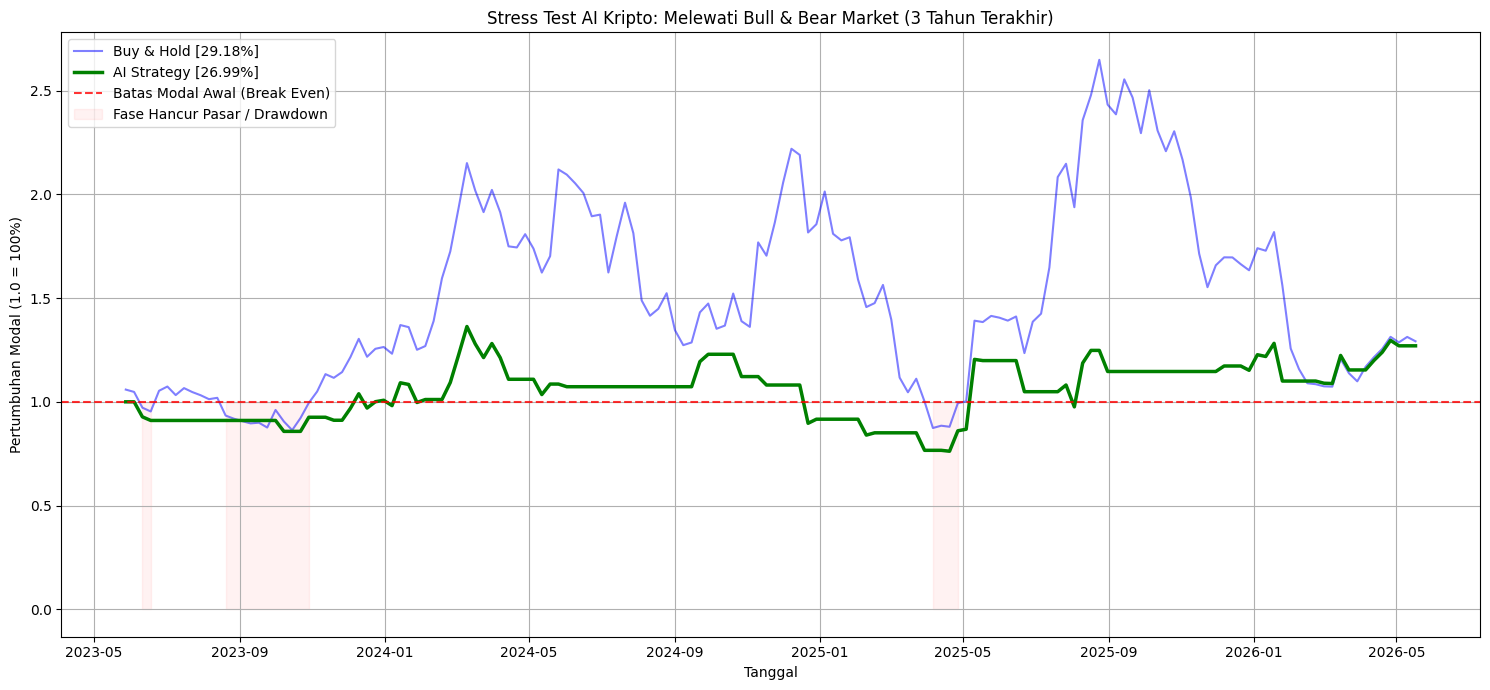

In [14]:
import pandas as pd
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt
from autogluon.tabular import TabularDataset, TabularPredictor

# ---------------------------------------------------------
# 1. DOWNLOAD DATA (8 TAHUN) UNTUK BAHAN BELAJAR EXTRA
# ---------------------------------------------------------
print("Mengunduh data ETH-USD 8 Tahun...")
data = yf.download("ETH-USD", period="8y", interval="1d")

df_raw = pd.DataFrame()
df_raw['Date'] = pd.to_datetime(data.index).tz_localize(None)

if isinstance(data['Close'], pd.DataFrame):
    df_raw['Close'] = data['Close'].iloc[:, 0].astype(float).values
else:
    df_raw['Close'] = data['Close'].astype(float).values

df_raw = df_raw.set_index('Date')

# ---------------------------------------------------------
# 2. RESAMPLE MINGGUAN & FEATURE ENGINEERING
# ---------------------------------------------------------
print("Merombak ke Timeframe Mingguan...")
df_weekly = pd.DataFrame()
df_weekly['Close'] = df_raw['Close'].resample('W').last()

df_weekly['Weekly_Return'] = df_weekly['Close'].pct_change()

# Indikator Teknikal
delta = df_weekly['Close'].diff()
gain = (delta.where(delta > 0, 0)).rolling(window=14).mean()
loss = (-delta.where(delta < 0, 0)).rolling(window=14).mean()
rs = gain / loss
df_weekly['RSI_14'] = 100 - (100 / (1 + rs))

exp1 = df_weekly['Close'].ewm(span=12, adjust=False).mean()
exp2 = df_weekly['Close'].ewm(span=26, adjust=False).mean()
df_weekly['MACD_Hist'] = exp1 - exp2

df_weekly['Volatility_4w'] = df_weekly['Weekly_Return'].rolling(window=4).std()

# Target: 1 jika ditutup lebih tinggi minggu depan
df_weekly['Target'] = (df_weekly['Close'].shift(-1) > df_weekly['Close']).astype(int)
df_weekly = df_weekly.dropna()

# ---------------------------------------------------------
# 3. SPLIT DATA (UJI KETAHANAN 3 TAHUN = 156 MINGGU)
# ---------------------------------------------------------
test_weeks = 156 # 3 Tahun
train_df = df_weekly.iloc[:-test_weeks].copy()
test_df = df_weekly.iloc[-test_weeks:].copy()

train_data = TabularDataset(train_df.drop(columns=['Close']))
test_data = TabularDataset(test_df.drop(columns=['Close']))

print(f"\n--- SKENARIO STRESS TEST ---")
print(f"Bahan Belajar Mesin : {len(train_data)} Minggu")
print(f"Medan Ujian         : {len(test_data)} Minggu (Melewati Badai 2022)")

# ---------------------------------------------------------
# 4. TRAINING MODEL AI
# ---------------------------------------------------------
print("\nMelatih Model AutoGluon...")
predictor = TabularPredictor(label='Target', eval_metric='accuracy').fit(
    train_data, presets='best_quality', time_limit=180
)

# ---------------------------------------------------------
# 5. FILTER PROBABILITAS & BACKTESTING
# ---------------------------------------------------------
probabilities = predictor.predict_proba(test_data.drop(columns=['Target']))[1]

# THRESHOLD DITAIKKAN KE 65% UNTUK DEFENSE YANG LEBIH KUAT
THRESHOLD = 0.60 

test_df['Sinyal_Bot'] = (probabilities >= THRESHOLD).astype(int)

# Menghitung Keuntungan Ekuitas
test_df['Return_Strategi'] = test_df['Sinyal_Bot'].shift(1) * test_df['Weekly_Return']
test_df['Return_Strategi'] = test_df['Return_Strategi'].fillna(0)

test_df['Modal_Strategi'] = (1 + test_df['Return_Strategi']).cumprod()
test_df['Modal_Hold'] = (1 + test_df['Weekly_Return'].fillna(0)).cumprod()

profit_strategi = (test_df['Modal_Strategi'].iloc[-1] - 1) * 100
profit_hold = (test_df['Modal_Hold'].iloc[-1] - 1) * 100

print(f"\n--- HASIL UJI KETAHANAN 3 TAHUN (THRESHOLD {THRESHOLD*100}%) ---")
print(f"Total Eksekusi Buy : {test_df['Sinyal_Bot'].sum()} Minggu")
print(f"Profit AI Strategi : {profit_strategi:.2f}%")
print(f"Profit Buy & Hold  : {profit_hold:.2f}%")

# ---------------------------------------------------------
# 6. VISUALISASI STRESS TEST
# ---------------------------------------------------------
plt.figure(figsize=(15, 7))
plt.plot(test_df.index, test_df['Modal_Hold'], label=f'Buy & Hold [{profit_hold:.2f}%]', color='blue', alpha=0.5)
plt.plot(test_df.index, test_df['Modal_Strategi'], label=f'AI Strategy [{profit_strategi:.2f}%]', linewidth=2.5, color='green')

# Garis batas modal awal
plt.axhline(y=1.0, color='red', linestyle='--', alpha=0.8, label='Batas Modal Awal (Break Even)')

# Shading area berwarna merah saat Buy & Hold sedang rugi (Di bawah 1.0)
plt.fill_between(test_df.index, 0, 1, where=(test_df['Modal_Hold'] < 1), color='red', alpha=0.05, label='Fase Hancur Pasar / Drawdown')

plt.title(f'Stress Test AI Kripto: Melewati Bull & Bear Market (3 Tahun Terakhir)')
plt.xlabel('Tanggal')
plt.ylabel('Pertumbuhan Modal (1.0 = 100%)')
plt.legend(loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()

Mengunduh data ETH, S&P 500, dan Dolar AS (DXY)...


[*********************100%***********************]  3 of 3 completed
/var/folders/q2/2h4p204s56d3vhv_jx5hmc6m0000gn/T/ipykernel_58025/1300662551.py:27: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df_raw['SP500_Close'] = data['Close']['^GSPC'].fillna(method='ffill').values
/var/folders/q2/2h4p204s56d3vhv_jx5hmc6m0000gn/T/ipykernel_58025/1300662551.py:28: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df_raw['DXY_Close'] = data['Close']['DX-Y.NYB'].fillna(method='ffill').values
No path specified. Models will be saved in: "AutogluonModels/ag-20260511_173701"
Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.5.0
Python Version:     3.12.7
Operating System:   Darwin
Platform Machine:   arm64
Platform Version:   Darwin Kernel Version 25.2.0: Tue Nov 18 21:03:25

Resample Mingguan & Menghitung Fitur Tingkat Lanjut...

Melatih Model AutoGluon dengan Makro Features...


Beginning AutoGluon training ... Time limit = 60s
AutoGluon will save models to "/Applications/MAMP/htdocs/local/kodingakademi/Python/python 4/bootcamp batch 3/final/AutogluonModels/ag-20260511_173701/ds_sub_fit/sub_fit_ho"
Train Data Rows:    188
Train Data Columns: 8
Label Column:       Target
Problem Type:       binary
Preprocessing data ...
Selected class <--> label mapping:  class 1 = 1, class 0 = 0
Using Feature Generators to preprocess the data ...
Fitting AutoMLPipelineFeatureGenerator...
	Available Memory:                    1808.07 MB
	Train Data (Original)  Memory Usage: 0.01 MB (0.0% of available memory)
	Inferring data type of each feature based on column values. Set feature_metadata_in to manually specify special dtypes of the features.
	Stage 1 Generators:
		Fitting AsTypeFeatureGenerator...
	Stage 2 Generators:
		Fitting FillNaFeatureGenerator...
	Stage 3 Generators:
		Fitting IdentityFeatureGenerator...
	Stage 4 Generators:
		Fitting DropUniqueFeatureGenerator...
	Stag


Menjalankan Backtest dengan Manajemen Risiko Institusional...

--- HASIL UJI KETAHANAN 3 TAHUN (ARSITEKTUR QUANT) ---
Total Eksekusi Parsial/Full : 83 Minggu
Berapa Kali Stop Loss Kena  : 40 Kali
Profit AI Strategi          : 46.98%
Profit Buy & Hold           : 29.22%


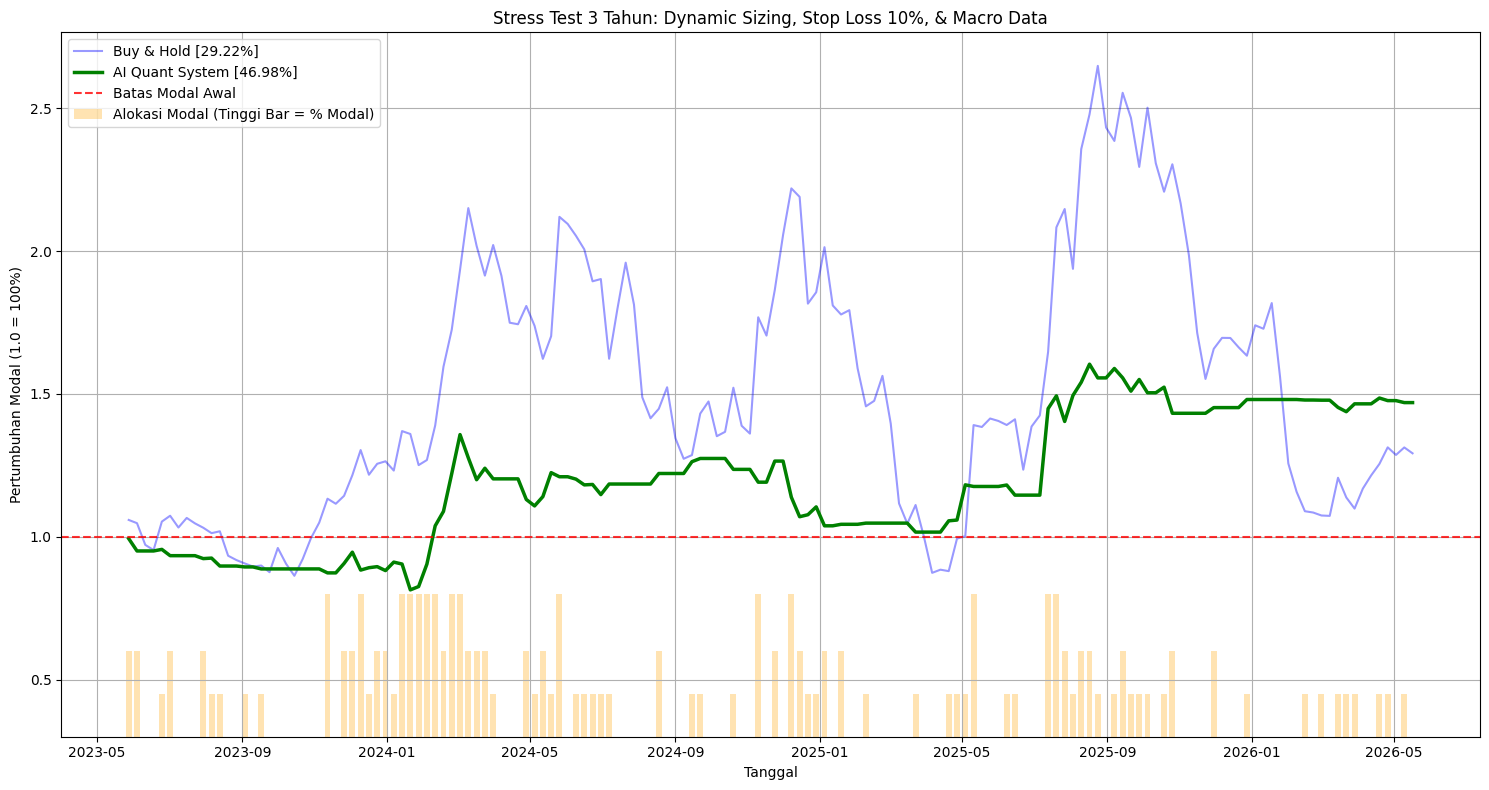

In [18]:
import pandas as pd
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt
from autogluon.tabular import TabularDataset, TabularPredictor

# ---------------------------------------------------------
# 1. DOWNLOAD MULTIPLE ASSETS & MAKRO DATA (8 TAHUN)
# ---------------------------------------------------------
print("Mengunduh data ETH, S&P 500, dan Dolar AS (DXY)...")
# Mengunduh 3 aset sekaligus
tickers = ["ETH-USD", "^GSPC", "DX-Y.NYB"]
data = yf.download(tickers, period="8y", interval="1d")

# Membuat DataFrame khusus dengan menangani MultiIndex dari yfinance
df_raw = pd.DataFrame()
df_raw['Date'] = pd.to_datetime(data.index).tz_localize(None)

# Ekstraksi Close dan Handle MultiIndex
df_raw['ETH_Close'] = data['Close']['ETH-USD'].values
df_raw['ETH_Open'] = data['Open']['ETH-USD'].values
df_raw['ETH_High'] = data['High']['ETH-USD'].values
df_raw['ETH_Low'] = data['Low']['ETH-USD'].values
df_raw['ETH_Volume'] = data['Volume']['ETH-USD'].values

# Data Makro (Saham & Dolar libur saat weekend, jadi kita gunakan forward fill)
df_raw['SP500_Close'] = data['Close']['^GSPC'].fillna(method='ffill').values
df_raw['DXY_Close'] = data['Close']['DX-Y.NYB'].fillna(method='ffill').values

df_raw = df_raw.set_index('Date')

# ---------------------------------------------------------
# 2. RESAMPLE MINGGUAN DENGAN LOGIKA OHLCV
# ---------------------------------------------------------
print("Resample Mingguan & Menghitung Fitur Tingkat Lanjut...")
df_weekly = pd.DataFrame()

# Untuk Stop Loss nanti, kita butuh Open, High, Low, Close Mingguan
df_weekly['Open'] = df_raw['ETH_Open'].resample('W').first()
df_weekly['High'] = df_raw['ETH_High'].resample('W').max()
df_weekly['Low'] = df_raw['ETH_Low'].resample('W').min()
df_weekly['Close'] = df_raw['ETH_Close'].resample('W').last()
df_weekly['Volume'] = df_raw['ETH_Volume'].resample('W').sum()

# Data Makro Mingguan
df_weekly['SP500_Close'] = df_raw['SP500_Close'].resample('W').last()
df_weekly['DXY_Close'] = df_raw['DXY_Close'].resample('W').last()

df_weekly['Weekly_Return'] = df_weekly['Close'].pct_change()

# --- A. Fitur Kripto (Momentum & Siklus) ---
delta = df_weekly['Close'].diff()
gain = (delta.where(delta > 0, 0)).rolling(window=14).mean()
loss = (-delta.where(delta < 0, 0)).rolling(window=14).mean()
df_weekly['RSI_14'] = 100 - (100 / (1 + (gain / loss)))

exp1 = df_weekly['Close'].ewm(span=12, adjust=False).mean()
exp2 = df_weekly['Close'].ewm(span=26, adjust=False).mean()
df_weekly['MACD_Hist'] = exp1 - exp2
df_weekly['Volatility_4w'] = df_weekly['Weekly_Return'].rolling(window=4).std()

df_weekly['SMA_50'] = df_weekly['Close'].rolling(window=50).mean()
df_weekly['Harga_vs_SMA50'] = df_weekly['Close'] / df_weekly['SMA_50']

df_weekly['High_52w'] = df_weekly['Close'].rolling(window=52).max()
df_weekly['Drawdown_52w'] = (df_weekly['Close'] / df_weekly['High_52w']) - 1

# --- B. Fitur Makroekonomi (Korelasi Eksternal) ---
# Mengukur performa SP500 dan Dolar minggu ini (Kripto biasanya berlawanan dengan Dolar)
df_weekly['SP500_Return'] = df_weekly['SP500_Close'].pct_change()
df_weekly['DXY_Return'] = df_weekly['DXY_Close'].pct_change()

# Target Klasifikasi
df_weekly['Target'] = (df_weekly['Close'].shift(-1) > df_weekly['Close']).astype(int)
df_weekly = df_weekly.dropna()

# ---------------------------------------------------------
# 3. SPLIT DATA (3 TAHUN STRESS TEST)
# ---------------------------------------------------------
test_weeks = 156 
train_df = df_weekly.iloc[:-test_weeks].copy()
test_df = df_weekly.iloc[-test_weeks:].copy()

# Buang nilai absolut agar tidak overfitting
kolom_dibuang = ['Open', 'High', 'Low', 'Close', 'Volume', 'SMA_50', 'High_52w', 'SP500_Close', 'DXY_Close']

train_data = TabularDataset(train_df.drop(columns=kolom_dibuang))
test_data = TabularDataset(test_df.drop(columns=kolom_dibuang))

# ---------------------------------------------------------
# 4. TRAINING MODEL AI
# ---------------------------------------------------------
print("\nMelatih Model AutoGluon dengan Makro Features...")
predictor = TabularPredictor(label='Target', eval_metric='accuracy').fit(
    train_data, presets='best_quality', time_limit=240 # Waktu dinaikkan karena fitur bertambah
)

# ---------------------------------------------------------
# 5. DYNAMIC POSITION SIZING & INTRA-WEEK STOP LOSS
# ---------------------------------------------------------
print("\nMenjalankan Backtest dengan Manajemen Risiko Institusional...")
probabilities = predictor.predict_proba(test_data.drop(columns=['Target']))[1]
test_df['Probabilitas_AI'] = probabilities

# LOGIKA DYNAMIC POSITION SIZING
# Fungsi untuk menentukan persentase modal yang digunakan berdasarkan probabilitas
def tentukan_alokasi(prob):
    if prob < 0.55: return 0.0     # Cash / Tidak Beli
    elif prob < 0.65: return 0.30  # Risiko Rendah (30% Modal)
    elif prob < 0.75: return 0.60  # Risiko Sedang (60% Modal)
    else: return 1.0               # All-in (100% Modal)

test_df['Alokasi_Modal'] = test_df['Probabilitas_AI'].apply(tentukan_alokasi)

# LOGIKA INTRA-WEEK STOP LOSS (10%)
# Hitung seberapa dalam harga jatuh selama minggu depan terhadap harga beli (Close minggu ini)
test_df['Intraweek_Drop'] = (test_df['Low'].shift(-1) - test_df['Close']) / test_df['Close']

STOP_LOSS_PCT = -0.10 # Cut loss jika turun 10%
realized_returns = []

for i in range(len(test_df)):
    if i == len(test_df) - 1:
        realized_returns.append(0)
        break
        
    # Jika selama minggu berjalan harga menembus batas Stop Loss
    if test_df['Intraweek_Drop'].iloc[i] <= STOP_LOSS_PCT:
        realized_returns.append(STOP_LOSS_PCT) # Rugi dikunci di -10%
    else:
        # Jika aman, dapat full return penutupan minggu tersebut
        realized_returns.append(test_df['Weekly_Return'].iloc[i+1])

test_df['Realized_Return_Minggu_Depan'] = realized_returns

# Hitung Keuntungan Bersih (Return Asli x Alokasi Modal)
test_df['Return_Strategi'] = test_df['Alokasi_Modal'] * test_df['Realized_Return_Minggu_Depan']

# ---------------------------------------------------------
# 6. EVALUASI DAN VISUALISASI
# ---------------------------------------------------------
test_df['Modal_Strategi'] = (1 + test_df['Return_Strategi']).cumprod()
test_df['Modal_Hold'] = (1 + test_df['Weekly_Return'].fillna(0)).cumprod()

profit_strategi = (test_df['Modal_Strategi'].iloc[-1] - 1) * 100
profit_hold = (test_df['Modal_Hold'].iloc[-1] - 1) * 100

print(f"\n--- HASIL UJI KETAHANAN 3 TAHUN (ARSITEKTUR QUANT) ---")
print(f"Total Eksekusi Parsial/Full : {(test_df['Alokasi_Modal'] > 0).sum()} Minggu")
print(f"Berapa Kali Stop Loss Kena  : {(test_df['Intraweek_Drop'] <= STOP_LOSS_PCT).sum()} Kali")
print(f"Profit AI Strategi          : {profit_strategi:.2f}%")
print(f"Profit Buy & Hold           : {profit_hold:.2f}%")

plt.figure(figsize=(15, 8))
plt.plot(test_df.index, test_df['Modal_Hold'], label=f'Buy & Hold [{profit_hold:.2f}%]', color='blue', alpha=0.4)
plt.plot(test_df.index, test_df['Modal_Strategi'], label=f'AI Quant System [{profit_strategi:.2f}%]', linewidth=2.5, color='green')

# Visualisasi seberapa besar modal yang dideploy oleh AI (Dynamic Sizing bar) di bagian bawah
plt.bar(test_df.index, test_df['Alokasi_Modal'] * 0.5, bottom=0.3, width=5, color='orange', alpha=0.3, label='Alokasi Modal (Tinggi Bar = % Modal)')

plt.axhline(y=1.0, color='red', linestyle='--', alpha=0.8, label='Batas Modal Awal')
plt.title(f'Stress Test 3 Tahun: Dynamic Sizing, Stop Loss 10%, & Macro Data')
plt.xlabel('Tanggal')
plt.ylabel('Pertumbuhan Modal (1.0 = 100%)')
plt.legend(loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()

Mengunduh data ETH, S&P 500, dan Dolar AS (DXY)...


[*********************100%***********************]  3 of 3 completed
/var/folders/q2/2h4p204s56d3vhv_jx5hmc6m0000gn/T/ipykernel_58025/3112990117.py:23: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df_raw['SP500_Close'] = data['Close']['^GSPC'].fillna(method='ffill').values
/var/folders/q2/2h4p204s56d3vhv_jx5hmc6m0000gn/T/ipykernel_58025/3112990117.py:24: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df_raw['DXY_Close'] = data['Close']['DX-Y.NYB'].fillna(method='ffill').values
No path specified. Models will be saved in: "AutogluonModels/ag-20260511_180214"
Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.5.0
Python Version:     3.12.7
Operating System:   Darwin
Platform Machine:   arm64
Platform Version:   Darwin Kernel Version 25.2.0: Tue Nov 18 21:03:25

Resample Mingguan & Menghitung Fitur Tingkat Lanjut...

Melatih Model AutoGluon dengan Makro Features...


Beginning AutoGluon training ... Time limit = 60s
AutoGluon will save models to "/Applications/MAMP/htdocs/local/kodingakademi/Python/python 4/bootcamp batch 3/final/AutogluonModels/ag-20260511_180214/ds_sub_fit/sub_fit_ho"
Train Data Rows:    188
Train Data Columns: 8
Label Column:       Target
Problem Type:       binary
Preprocessing data ...
Selected class <--> label mapping:  class 1 = 1, class 0 = 0
Using Feature Generators to preprocess the data ...
Fitting AutoMLPipelineFeatureGenerator...
	Available Memory:                    1878.67 MB
	Train Data (Original)  Memory Usage: 0.01 MB (0.0% of available memory)
	Inferring data type of each feature based on column values. Set feature_metadata_in to manually specify special dtypes of the features.
	Stage 1 Generators:
		Fitting AsTypeFeatureGenerator...
	Stage 2 Generators:
		Fitting FillNaFeatureGenerator...
	Stage 3 Generators:
		Fitting IdentityFeatureGenerator...
	Stage 4 Generators:
		Fitting DropUniqueFeatureGenerator...
	Stag


Menjalankan Backtest Realistis (Termasuk Biaya & Slippage)...

--- HASIL UJI KETAHANAN 3 TAHUN (REAL-WORLD FRICTION) ---
Total Eksekusi Parsial/Full  : 84 Minggu
Berapa Kali Stop Loss Kena   : 40 Kali
Estimasi Total Biaya & Slip  : -11.68% (Telah dipotong dari profit)
Profit AI Strategi Bersih    : 30.68%
Profit Buy & Hold            : 29.54%


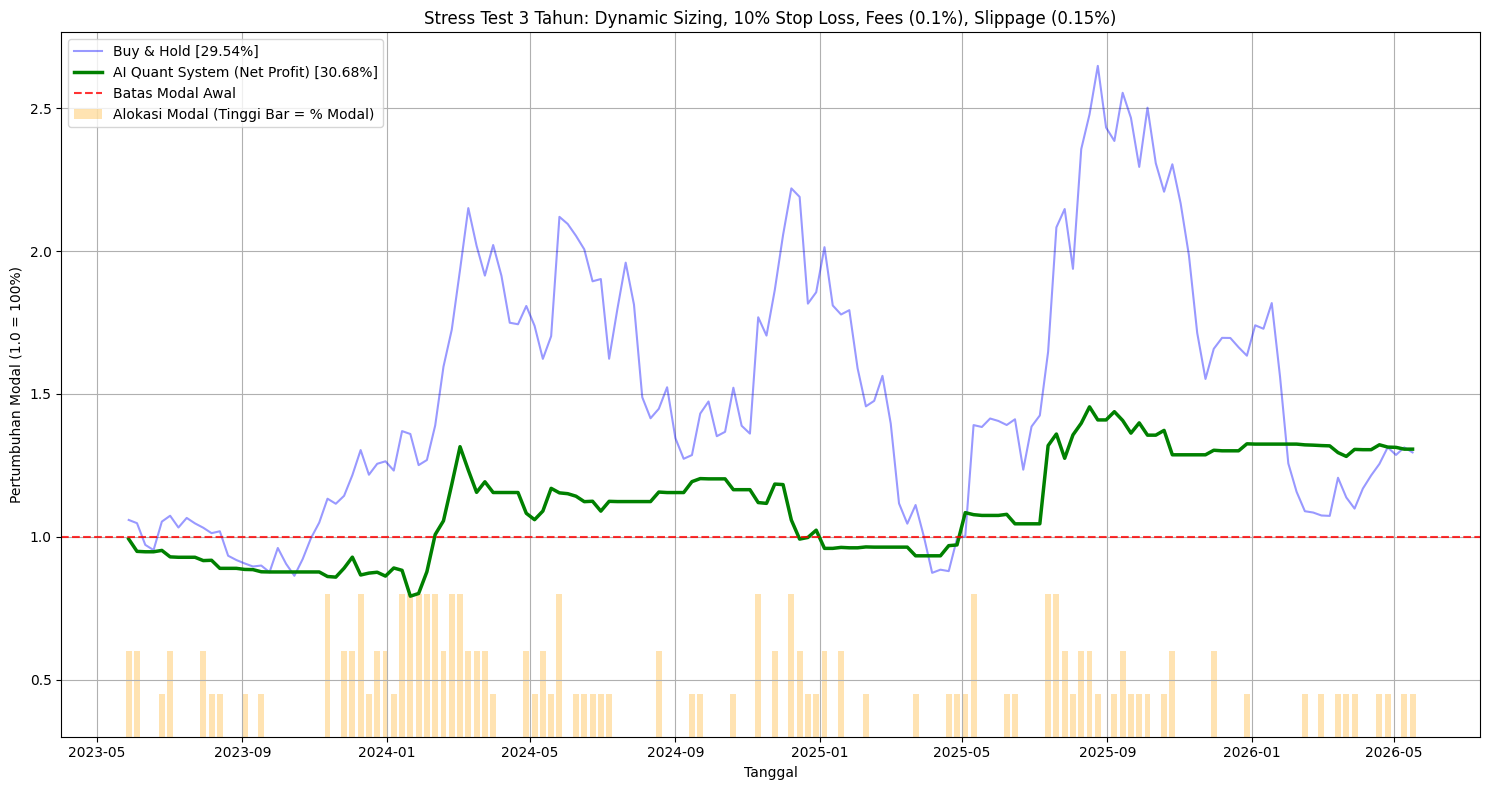

In [19]:
import pandas as pd
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt
from autogluon.tabular import TabularDataset, TabularPredictor

# ---------------------------------------------------------
# 1. DOWNLOAD MULTIPLE ASSETS & MAKRO DATA (8 TAHUN)
# ---------------------------------------------------------
print("Mengunduh data ETH, S&P 500, dan Dolar AS (DXY)...")
tickers = ["ETH-USD", "^GSPC", "DX-Y.NYB"]
data = yf.download(tickers, period="8y", interval="1d")

df_raw = pd.DataFrame()
df_raw['Date'] = pd.to_datetime(data.index).tz_localize(None)

if isinstance(data['Close'], pd.DataFrame):
    df_raw['ETH_Close'] = data['Close']['ETH-USD'].values
    df_raw['ETH_Open'] = data['Open']['ETH-USD'].values
    df_raw['ETH_High'] = data['High']['ETH-USD'].values
    df_raw['ETH_Low'] = data['Low']['ETH-USD'].values
    df_raw['ETH_Volume'] = data['Volume']['ETH-USD'].values
    df_raw['SP500_Close'] = data['Close']['^GSPC'].fillna(method='ffill').values
    df_raw['DXY_Close'] = data['Close']['DX-Y.NYB'].fillna(method='ffill').values
else:
    # Fallback jika hanya 1 ticker (meski di atas memanggil 3)
    pass

df_raw = df_raw.set_index('Date')

# ---------------------------------------------------------
# 2. RESAMPLE MINGGUAN & ADVANCED FEATURE ENGINEERING
# ---------------------------------------------------------
print("Resample Mingguan & Menghitung Fitur Tingkat Lanjut...")
df_weekly = pd.DataFrame()

df_weekly['Open'] = df_raw['ETH_Open'].resample('W').first()
df_weekly['High'] = df_raw['ETH_High'].resample('W').max()
df_weekly['Low'] = df_raw['ETH_Low'].resample('W').min()
df_weekly['Close'] = df_raw['ETH_Close'].resample('W').last()
df_weekly['Volume'] = df_raw['ETH_Volume'].resample('W').sum()

df_weekly['SP500_Close'] = df_raw['SP500_Close'].resample('W').last()
df_weekly['DXY_Close'] = df_raw['DXY_Close'].resample('W').last()

df_weekly['Weekly_Return'] = df_weekly['Close'].pct_change()

# --- A. Fitur Kripto (Momentum & Siklus) ---
delta = df_weekly['Close'].diff()
gain = (delta.where(delta > 0, 0)).rolling(window=14).mean()
loss = (-delta.where(delta < 0, 0)).rolling(window=14).mean()
df_weekly['RSI_14'] = 100 - (100 / (1 + (gain / loss)))

exp1 = df_weekly['Close'].ewm(span=12, adjust=False).mean()
exp2 = df_weekly['Close'].ewm(span=26, adjust=False).mean()
df_weekly['MACD_Hist'] = exp1 - exp2
df_weekly['Volatility_4w'] = df_weekly['Weekly_Return'].rolling(window=4).std()

df_weekly['SMA_50'] = df_weekly['Close'].rolling(window=50).mean()
df_weekly['Harga_vs_SMA50'] = df_weekly['Close'] / df_weekly['SMA_50']

df_weekly['High_52w'] = df_weekly['Close'].rolling(window=52).max()
df_weekly['Drawdown_52w'] = (df_weekly['Close'] / df_weekly['High_52w']) - 1

# --- B. Fitur Makroekonomi ---
df_weekly['SP500_Return'] = df_weekly['SP500_Close'].pct_change()
df_weekly['DXY_Return'] = df_weekly['DXY_Close'].pct_change()

df_weekly['Target'] = (df_weekly['Close'].shift(-1) > df_weekly['Close']).astype(int)
df_weekly = df_weekly.dropna()

# ---------------------------------------------------------
# 3. SPLIT DATA (3 TAHUN STRESS TEST)
# ---------------------------------------------------------
test_weeks = 156 
train_df = df_weekly.iloc[:-test_weeks].copy()
test_df = df_weekly.iloc[-test_weeks:].copy()

kolom_dibuang = ['Open', 'High', 'Low', 'Close', 'Volume', 'SMA_50', 'High_52w', 'SP500_Close', 'DXY_Close']

train_data = TabularDataset(train_df.drop(columns=kolom_dibuang))
test_data = TabularDataset(test_df.drop(columns=kolom_dibuang))

# ---------------------------------------------------------
# 4. TRAINING MODEL AI
# ---------------------------------------------------------
print("\nMelatih Model AutoGluon dengan Makro Features...")
predictor = TabularPredictor(label='Target', eval_metric='accuracy').fit(
    train_data, presets='best_quality', time_limit=240
)

# ---------------------------------------------------------
# 5. DYNAMIC POSITION SIZING, STOP LOSS, & FRICTION COSTS
# ---------------------------------------------------------
print("\nMenjalankan Backtest Realistis (Termasuk Biaya & Slippage)...")
probabilities = predictor.predict_proba(test_data.drop(columns=['Target']))[1]
test_df['Probabilitas_AI'] = probabilities

# Konfigurasi Friksi Pasar
FEE_PCT = 0.001       # 0.1% Biaya Transaksi
SLIPPAGE_PCT = 0.0015 # 0.15% Slippage
TOTAL_COST_PCT = FEE_PCT + SLIPPAGE_PCT
STOP_LOSS_PCT = -0.10 # -10% Stop Loss

def tentukan_alokasi(prob):
    if prob < 0.55: return 0.0
    elif prob < 0.65: return 0.30
    elif prob < 0.75: return 0.60
    else: return 1.0

test_df['Alokasi_Modal'] = test_df['Probabilitas_AI'].apply(tentukan_alokasi)
test_df['Intraweek_Drop'] = (test_df['Low'].shift(-1) - test_df['Close']) / test_df['Close']

realized_returns = []
biaya_transaksi_list = []
prev_alokasi = 0.0

# Loop untuk menghitung pergerakan mingguan dengan biaya yang akurat
for i in range(len(test_df)):
    current_alokasi = test_df['Alokasi_Modal'].iloc[i]
    
    # 1. Biaya masuk/keluar di awal minggu (hanya berdasarkan selisih perubahan alokasi)
    delta_alokasi = abs(current_alokasi - prev_alokasi)
    biaya_masuk = delta_alokasi * TOTAL_COST_PCT
    
    if i == len(test_df) - 1:
        realized_returns.append(0)
        biaya_transaksi_list.append(biaya_masuk)
        break
        
    # 2. Cek apakah Stop Loss tersentuh di tengah minggu
    intraweek_drop = test_df['Intraweek_Drop'].iloc[i]
    
    if intraweek_drop <= STOP_LOSS_PCT:
        # Stop Loss tersentuh: Kunci kerugian di -10%
        return_minggu_ini = STOP_LOSS_PCT
        # Karena jual paksa, ada biaya keluar untuk seluruh alokasi yang sedang dipegang
        biaya_keluar = current_alokasi * TOTAL_COST_PCT
        # Set prev_alokasi jadi 0 karena semua posisi sudah dilikuidasi di tengah jalan
        prev_alokasi = 0.0 
    else:
        # Aman, dapatkan return mingguan penuh
        return_minggu_ini = test_df['Weekly_Return'].iloc[i+1]
        biaya_keluar = 0.0
        # Simpan alokasi saat ini untuk minggu depan
        prev_alokasi = current_alokasi
        
    realized_returns.append(return_minggu_ini)
    biaya_transaksi_list.append(biaya_masuk + biaya_keluar)

test_df['Realized_Return_Minggu_Depan'] = realized_returns
test_df['Total_Biaya_Friction'] = biaya_transaksi_list

# Hitung Return Bersih = (Alokasi * Return Kasar) - Biaya Transaksi & Slippage
test_df['Return_Strategi_Bersih'] = (test_df['Alokasi_Modal'] * test_df['Realized_Return_Minggu_Depan']) - test_df['Total_Biaya_Friction']

# ---------------------------------------------------------
# 6. EVALUASI DAN VISUALISASI
# ---------------------------------------------------------
test_df['Modal_Strategi'] = (1 + test_df['Return_Strategi_Bersih']).cumprod()
test_df['Modal_Hold'] = (1 + test_df['Weekly_Return'].fillna(0)).cumprod()

profit_strategi = (test_df['Modal_Strategi'].iloc[-1] - 1) * 100
profit_hold = (test_df['Modal_Hold'].iloc[-1] - 1) * 100
total_biaya_terakumulasi = test_df['Total_Biaya_Friction'].sum() * 100

print(f"\n--- HASIL UJI KETAHANAN 3 TAHUN (REAL-WORLD FRICTION) ---")
print(f"Total Eksekusi Parsial/Full  : {(test_df['Alokasi_Modal'] > 0).sum()} Minggu")
print(f"Berapa Kali Stop Loss Kena   : {(test_df['Intraweek_Drop'] <= STOP_LOSS_PCT).sum()} Kali")
print(f"Estimasi Total Biaya & Slip  : -{total_biaya_terakumulasi:.2f}% (Telah dipotong dari profit)")
print(f"Profit AI Strategi Bersih    : {profit_strategi:.2f}%")
print(f"Profit Buy & Hold            : {profit_hold:.2f}%")

plt.figure(figsize=(15, 8))
plt.plot(test_df.index, test_df['Modal_Hold'], label=f'Buy & Hold [{profit_hold:.2f}%]', color='blue', alpha=0.4)
plt.plot(test_df.index, test_df['Modal_Strategi'], label=f'AI Quant System (Net Profit) [{profit_strategi:.2f}%]', linewidth=2.5, color='green')

# Visualisasi alokasi modal
plt.bar(test_df.index, test_df['Alokasi_Modal'] * 0.5, bottom=0.3, width=5, color='orange', alpha=0.3, label='Alokasi Modal (Tinggi Bar = % Modal)')

plt.axhline(y=1.0, color='red', linestyle='--', alpha=0.8, label='Batas Modal Awal')
plt.title(f'Stress Test 3 Tahun: Dynamic Sizing, 10% Stop Loss, Fees (0.1%), Slippage (0.15%)')
plt.xlabel('Tanggal')
plt.ylabel('Pertumbuhan Modal (1.0 = 100%)')
plt.legend(loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()

Mengunduh data ETH, S&P 500, dan Dolar AS (DXY)...


[*********************100%***********************]  3 of 3 completed
/var/folders/q2/2h4p204s56d3vhv_jx5hmc6m0000gn/T/ipykernel_58025/1540661988.py:23: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df_raw['SP500_Close'] = data['Close']['^GSPC'].fillna(method='ffill').values
/var/folders/q2/2h4p204s56d3vhv_jx5hmc6m0000gn/T/ipykernel_58025/1540661988.py:24: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df_raw['DXY_Close'] = data['Close']['DX-Y.NYB'].fillna(method='ffill').values
No path specified. Models will be saved in: "AutogluonModels/ag-20260511_183220"
Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.5.0
Python Version:     3.12.7
Operating System:   Darwin
Platform Machine:   arm64
Platform Version:   Darwin Kernel Version 25.2.0: Tue Nov 18 21:03:25

Resample Mingguan & Menghitung Fitur Makro serta ATR...

Melatih Model AutoGluon dengan Makro Features...


Beginning AutoGluon training ... Time limit = 60s
AutoGluon will save models to "/Applications/MAMP/htdocs/local/kodingakademi/Python/python 4/bootcamp batch 3/final/AutogluonModels/ag-20260511_183220/ds_sub_fit/sub_fit_ho"
Train Data Rows:    188
Train Data Columns: 9
Label Column:       Target
Problem Type:       binary
Preprocessing data ...
Selected class <--> label mapping:  class 1 = 1, class 0 = 0
Using Feature Generators to preprocess the data ...
Fitting AutoMLPipelineFeatureGenerator...
	Available Memory:                    1983.06 MB
	Train Data (Original)  Memory Usage: 0.01 MB (0.0% of available memory)
	Inferring data type of each feature based on column values. Set feature_metadata_in to manually specify special dtypes of the features.
	Stage 1 Generators:
		Fitting AsTypeFeatureGenerator...
	Stage 2 Generators:
		Fitting FillNaFeatureGenerator...
	Stage 3 Generators:
		Fitting IdentityFeatureGenerator...
	Stage 4 Generators:
		Fitting DropUniqueFeatureGenerator...
	Stag


Menjalankan Backtest Realistis (Trailing ATR Stop & Biaya)...

--- HASIL UJI KETAHANAN 3 TAHUN (TRAILING ATR STOP) ---
Total Eksekusi Parsial/Full  : 71 Minggu
Berapa Kali Stop Loss Kena   : 6 Kali
Estimasi Total Biaya & Slip  : -11.58% (Telah dipotong dari profit)
Profit AI Strategi Bersih    : 24.13%
Profit Buy & Hold            : 29.78%


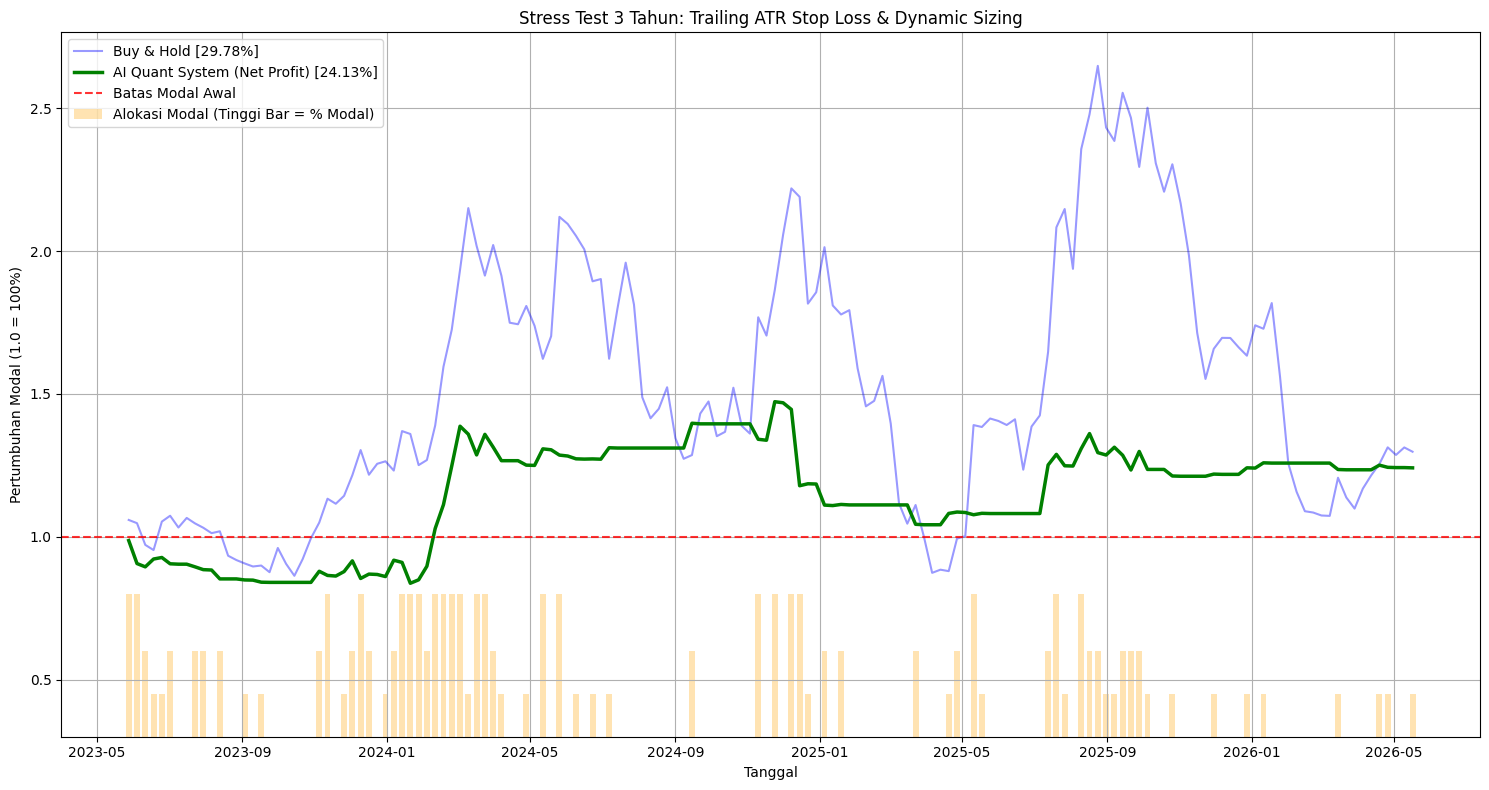

In [21]:
import pandas as pd
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt
from autogluon.tabular import TabularDataset, TabularPredictor

# ---------------------------------------------------------
# 1. DOWNLOAD MULTIPLE ASSETS & MAKRO DATA (8 TAHUN)
# ---------------------------------------------------------
print("Mengunduh data ETH, S&P 500, dan Dolar AS (DXY)...")
tickers = ["ETH-USD", "^GSPC", "DX-Y.NYB"]
data = yf.download(tickers, period="8y", interval="1d")

df_raw = pd.DataFrame()
df_raw['Date'] = pd.to_datetime(data.index).tz_localize(None)

if isinstance(data['Close'], pd.DataFrame):
    df_raw['ETH_Close'] = data['Close']['ETH-USD'].values
    df_raw['ETH_Open'] = data['Open']['ETH-USD'].values
    df_raw['ETH_High'] = data['High']['ETH-USD'].values
    df_raw['ETH_Low'] = data['Low']['ETH-USD'].values
    df_raw['ETH_Volume'] = data['Volume']['ETH-USD'].values
    df_raw['SP500_Close'] = data['Close']['^GSPC'].fillna(method='ffill').values
    df_raw['DXY_Close'] = data['Close']['DX-Y.NYB'].fillna(method='ffill').values
else:
    pass

df_raw = df_raw.set_index('Date')

# ---------------------------------------------------------
# 2. RESAMPLE MINGGUAN & ADVANCED FEATURE ENGINEERING
# ---------------------------------------------------------
print("Resample Mingguan & Menghitung Fitur Makro serta ATR...")
df_weekly = pd.DataFrame()

df_weekly['Open'] = df_raw['ETH_Open'].resample('W').first()
df_weekly['High'] = df_raw['ETH_High'].resample('W').max()
df_weekly['Low'] = df_raw['ETH_Low'].resample('W').min()
df_weekly['Close'] = df_raw['ETH_Close'].resample('W').last()
df_weekly['Volume'] = df_raw['ETH_Volume'].resample('W').sum()

df_weekly['SP500_Close'] = df_raw['SP500_Close'].resample('W').last()
df_weekly['DXY_Close'] = df_raw['DXY_Close'].resample('W').last()

df_weekly['Weekly_Return'] = df_weekly['Close'].pct_change()

# --- A. Menghitung ATR (Average True Range) untuk Volatilitas ---
prev_close = df_weekly['Close'].shift(1)
tr1 = df_weekly['High'] - df_weekly['Low']
tr2 = (df_weekly['High'] - prev_close).abs()
tr3 = (df_weekly['Low'] - prev_close).abs()
df_weekly['TR'] = pd.DataFrame({'tr1': tr1, 'tr2': tr2, 'tr3': tr3}).max(axis=1)

# ATR 4 Minggu (Disajikan dalam persentase terhadap harga)
df_weekly['ATR_4w'] = df_weekly['TR'].rolling(window=4).mean()
df_weekly['ATR_Pct'] = df_weekly['ATR_4w'] / df_weekly['Close']

# --- B. Fitur Kripto (Momentum & Siklus) ---
delta = df_weekly['Close'].diff()
gain = (delta.where(delta > 0, 0)).rolling(window=14).mean()
loss = (-delta.where(delta < 0, 0)).rolling(window=14).mean()
df_weekly['RSI_14'] = 100 - (100 / (1 + (gain / loss)))

exp1 = df_weekly['Close'].ewm(span=12, adjust=False).mean()
exp2 = df_weekly['Close'].ewm(span=26, adjust=False).mean()
df_weekly['MACD_Hist'] = exp1 - exp2
df_weekly['Volatility_4w'] = df_weekly['Weekly_Return'].rolling(window=4).std()

df_weekly['SMA_50'] = df_weekly['Close'].rolling(window=50).mean()
df_weekly['Harga_vs_SMA50'] = df_weekly['Close'] / df_weekly['SMA_50']

df_weekly['High_52w'] = df_weekly['Close'].rolling(window=52).max()
df_weekly['Drawdown_52w'] = (df_weekly['Close'] / df_weekly['High_52w']) - 1

# --- C. Fitur Makroekonomi ---
df_weekly['SP500_Return'] = df_weekly['SP500_Close'].pct_change()
df_weekly['DXY_Return'] = df_weekly['DXY_Close'].pct_change()

df_weekly['Target'] = (df_weekly['Close'].shift(-1) > df_weekly['Close']).astype(int)
df_weekly = df_weekly.dropna()

# ---------------------------------------------------------
# 3. SPLIT DATA (3 TAHUN STRESS TEST)
# ---------------------------------------------------------
test_weeks = 156 
train_df = df_weekly.iloc[:-test_weeks].copy()
test_df = df_weekly.iloc[-test_weeks:].copy()

# Buang nilai absolut & variabel yang tidak perlu dipelajari oleh model
kolom_dibuang = ['Open', 'High', 'Low', 'Close', 'Volume', 'TR', 'ATR_4w', 'SMA_50', 'High_52w', 'SP500_Close', 'DXY_Close']

train_data = TabularDataset(train_df.drop(columns=kolom_dibuang))
test_data = TabularDataset(test_df.drop(columns=kolom_dibuang))

# ---------------------------------------------------------
# 4. TRAINING MODEL AI
# ---------------------------------------------------------
print("\nMelatih Model AutoGluon dengan Makro Features...")
predictor = TabularPredictor(label='Target', eval_metric='accuracy').fit(
    train_data, presets='best_quality', time_limit=240
)

# ---------------------------------------------------------
# 5. LOGIKA DYNAMIC SIZING + TRAILING ATR STOP + FRICTIONS
# ---------------------------------------------------------
print("\nMenjalankan Backtest Realistis (Trailing ATR Stop & Biaya)...")
probabilities = predictor.predict_proba(test_data.drop(columns=['Target']))[1]
test_df['Probabilitas_AI'] = probabilities

# Konfigurasi Friksi Pasar
FEE_PCT = 0.001       # 0.1% Biaya Transaksi
SLIPPAGE_PCT = 0.0015 # 0.15% Slippage
TOTAL_COST_PCT = FEE_PCT + SLIPPAGE_PCT

def tentukan_alokasi(prob):
    if prob < 0.55: return 0.0
    elif prob < 0.65: return 0.30
    elif prob < 0.75: return 0.60
    else: return 1.0

test_df['Alokasi_Modal'] = test_df['Probabilitas_AI'].apply(tentukan_alokasi)

realized_returns = []
biaya_transaksi_list = []
jumlah_stop_loss_kena = 0

prev_alokasi = 0.0
highest_price_since_entry = 0.0

# Loop Utama Simulasi
for i in range(len(test_df)):
    current_alokasi = test_df['Alokasi_Modal'].iloc[i]
    current_close = test_df['Close'].iloc[i]
    current_atr_pct = test_df['ATR_Pct'].iloc[i]
    
    # 1. Biaya masuk berdasarkan selisih alokasi
    delta_alokasi = abs(current_alokasi - prev_alokasi)
    biaya_masuk = delta_alokasi * TOTAL_COST_PCT
    
    if i == len(test_df) - 1:
        realized_returns.append(0)
        biaya_transaksi_list.append(biaya_masuk)
        break
        
    next_low = test_df['Low'].iloc[i+1]
    
    # 2. Logika Dynamic Trailing Stop (Hanya aktif jika sedang holding)
    if current_alokasi > 0:
        if prev_alokasi == 0:
            # Jika baru buka posisi minggu ini, harga tertinggi adalah harga penutupan saat ini
            highest_price_since_entry = current_close
        else:
            # Perbarui harga tertinggi (Watermark)
            highest_price_since_entry = max(highest_price_since_entry, current_close)
        
        # Hitung Ambang Batas Stop Loss
        # Minimal 5% agar tidak terlalu ketat, atau 1.5x volatilitas rata-rata (ATR)
        dynamic_sl_pct = max(0.05, 1.5 * current_atr_pct) 
        sl_price = highest_price_since_entry * (1 - dynamic_sl_pct)
        
        # Cek apakah minggu depan harga sempat anjlok menembus harga Stop Loss
        if next_low <= sl_price:
            # Kena Trailing Stop! Kunci kerugian dari harga penutupan minggu ini ke harga SL
            return_minggu_ini = (sl_price - current_close) / current_close
            biaya_keluar = current_alokasi * TOTAL_COST_PCT
            
            # Reset semua status posisi karena sudah likuidasi
            prev_alokasi = 0.0 
            highest_price_since_entry = 0.0
            jumlah_stop_loss_kena += 1
        else:
            # Aman, tren masih terjaga, ambil return penuh
            return_minggu_ini = test_df['Weekly_Return'].iloc[i+1]
            biaya_keluar = 0.0
            prev_alokasi = current_alokasi
            
    else:
        # Jika sedang memegang Cash (Alokasi = 0)
        return_minggu_ini = 0.0
        biaya_keluar = 0.0
        prev_alokasi = 0.0
        highest_price_since_entry = 0.0
        
    realized_returns.append(return_minggu_ini)
    biaya_transaksi_list.append(biaya_masuk + biaya_keluar)

test_df['Realized_Return_Minggu_Depan'] = realized_returns
test_df['Total_Biaya_Friction'] = biaya_transaksi_list

# Hitung Return Bersih = (Alokasi * Return Kasar) - Biaya Transaksi & Slippage
test_df['Return_Strategi_Bersih'] = (test_df['Alokasi_Modal'] * test_df['Realized_Return_Minggu_Depan']) - test_df['Total_Biaya_Friction']

# ---------------------------------------------------------
# 6. EVALUASI DAN VISUALISASI
# ---------------------------------------------------------
test_df['Modal_Strategi'] = (1 + test_df['Return_Strategi_Bersih']).cumprod()
test_df['Modal_Hold'] = (1 + test_df['Weekly_Return'].fillna(0)).cumprod()

profit_strategi = (test_df['Modal_Strategi'].iloc[-1] - 1) * 100
profit_hold = (test_df['Modal_Hold'].iloc[-1] - 1) * 100
total_biaya_terakumulasi = test_df['Total_Biaya_Friction'].sum() * 100

print(f"\n--- HASIL UJI KETAHANAN 3 TAHUN (TRAILING ATR STOP) ---")
print(f"Total Eksekusi Parsial/Full  : {(test_df['Alokasi_Modal'] > 0).sum()} Minggu")
print(f"Berapa Kali Stop Loss Kena   : {jumlah_stop_loss_kena} Kali")
print(f"Estimasi Total Biaya & Slip  : -{total_biaya_terakumulasi:.2f}% (Telah dipotong dari profit)")
print(f"Profit AI Strategi Bersih    : {profit_strategi:.2f}%")
print(f"Profit Buy & Hold            : {profit_hold:.2f}%")

plt.figure(figsize=(15, 8))
plt.plot(test_df.index, test_df['Modal_Hold'], label=f'Buy & Hold [{profit_hold:.2f}%]', color='blue', alpha=0.4)
plt.plot(test_df.index, test_df['Modal_Strategi'], label=f'AI Quant System (Net Profit) [{profit_strategi:.2f}%]', linewidth=2.5, color='green')

plt.bar(test_df.index, test_df['Alokasi_Modal'] * 0.5, bottom=0.3, width=5, color='orange', alpha=0.3, label='Alokasi Modal (Tinggi Bar = % Modal)')

plt.axhline(y=1.0, color='red', linestyle='--', alpha=0.8, label='Batas Modal Awal')
plt.title(f'Stress Test 3 Tahun: Trailing ATR Stop Loss & Dynamic Sizing')
plt.xlabel('Tanggal')
plt.ylabel('Pertumbuhan Modal (1.0 = 100%)')
plt.legend(loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()

Mengunduh data ETH, S&P 500, dan Dolar AS (DXY)...
YF.download() has changed argument auto_adjust default to True


[*********************100%***********************]  3 of 3 completed
/var/folders/q2/2h4p204s56d3vhv_jx5hmc6m0000gn/T/ipykernel_2453/1399639252.py:23: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df_raw['SP500_Close'] = data['Close']['^GSPC'].fillna(method='ffill').values
/var/folders/q2/2h4p204s56d3vhv_jx5hmc6m0000gn/T/ipykernel_2453/1399639252.py:24: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df_raw['DXY_Close'] = data['Close']['DX-Y.NYB'].fillna(method='ffill').values
No path specified. Models will be saved in: "AutogluonModels/ag-20260512_090426"
Verbosity: 2 (Standard Logging)


Resample Mingguan & Menghitung Fitur Makro...

Melatih Model AutoGluon dengan Makro Features...


=================== System Info ===================
AutoGluon Version:  1.5.0
Python Version:     3.12.7
Operating System:   Darwin
Platform Machine:   arm64
Platform Version:   Darwin Kernel Version 25.2.0: Tue Nov 18 21:03:25 PST 2025; root:xnu-12377.61.12~1/RELEASE_ARM64_T8122
CPU Count:          8
Pytorch Version:    2.9.1
CUDA Version:       CUDA is not available
GPU Count:          WARNING: Exception was raised when calculating GPU count (AssertionError)
Memory Avail:       1.80 GB / 8.00 GB (22.5%)
Disk Space Avail:   13.73 GB / 228.27 GB (6.0%)
Presets specified: ['best_quality']
Using hyperparameters preset: hyperparameters='zeroshot'
Setting dynamic_stacking from 'auto' to True. Reason: Enable dynamic_stacking when use_bag_holdout is disabled. (use_bag_holdout=False)
Stack configuration (auto_stack=True): num_stack_levels=1, num_bag_folds=8, num_bag_sets=1
DyStack is enabled (dynamic_stacking=True). AutoGluon will try to determine whether the input data is affected by stacked


Menjalankan Backtest dengan Hysteresis (Filter Anti-Bocor Fee)...

--- HASIL STRESS TEST (HYSTERESIS / THE LAZY BOT) ---
Total Frekuensi Transaksi Beli/Jual : 26 Kali dalam 3 Tahun
Total Biaya Friksi yang Dibakar     : -6.50% (Jauh lebih hemat!)
Profit AI Strategi (Bersih)         : 66.13%
Profit Buy & Hold                   : 26.79%


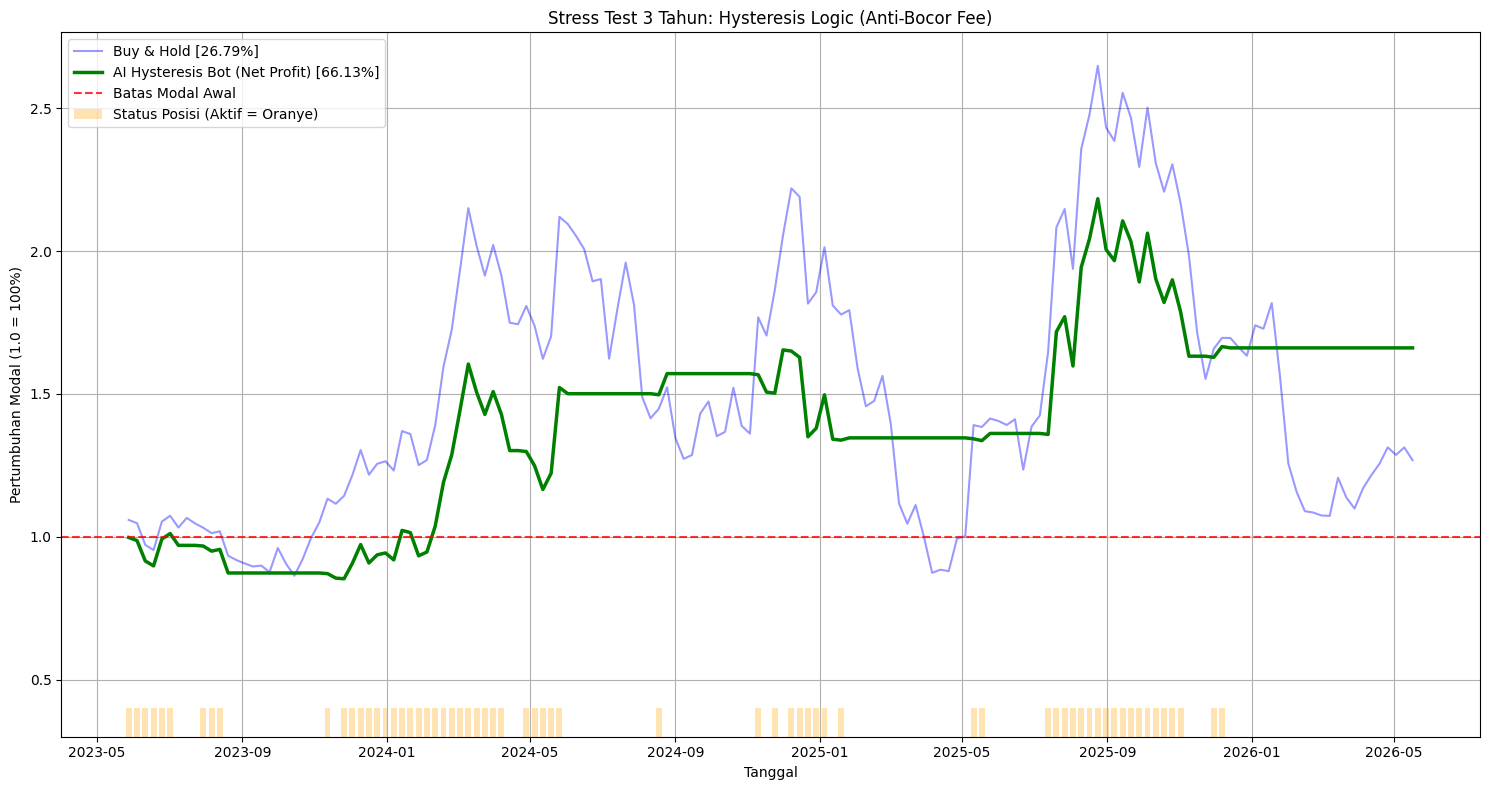

In [1]:
import pandas as pd
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt
from autogluon.tabular import TabularDataset, TabularPredictor

# ---------------------------------------------------------
# 1. DOWNLOAD MULTIPLE ASSETS & MAKRO DATA (8 TAHUN)
# ---------------------------------------------------------
print("Mengunduh data ETH, S&P 500, dan Dolar AS (DXY)...")
tickers = ["ETH-USD", "^GSPC", "DX-Y.NYB"]
data = yf.download(tickers, period="8y", interval="1d")

df_raw = pd.DataFrame()
df_raw['Date'] = pd.to_datetime(data.index).tz_localize(None)

if isinstance(data['Close'], pd.DataFrame):
    df_raw['ETH_Close'] = data['Close']['ETH-USD'].values
    df_raw['ETH_Open'] = data['Open']['ETH-USD'].values
    df_raw['ETH_High'] = data['High']['ETH-USD'].values
    df_raw['ETH_Low'] = data['Low']['ETH-USD'].values
    df_raw['ETH_Volume'] = data['Volume']['ETH-USD'].values
    df_raw['SP500_Close'] = data['Close']['^GSPC'].fillna(method='ffill').values
    df_raw['DXY_Close'] = data['Close']['DX-Y.NYB'].fillna(method='ffill').values
else:
    pass

df_raw = df_raw.set_index('Date')

# ---------------------------------------------------------
# 2. RESAMPLE MINGGUAN & ADVANCED FEATURE ENGINEERING
# ---------------------------------------------------------
print("Resample Mingguan & Menghitung Fitur Makro...")
df_weekly = pd.DataFrame()

df_weekly['Close'] = df_raw['ETH_Close'].resample('W').last()
df_weekly['Volume'] = df_raw['ETH_Volume'].resample('W').sum()
df_weekly['SP500_Close'] = df_raw['SP500_Close'].resample('W').last()
df_weekly['DXY_Close'] = df_raw['DXY_Close'].resample('W').last()

df_weekly['Weekly_Return'] = df_weekly['Close'].pct_change()

# --- A. Fitur Kripto (Momentum & Siklus) ---
delta = df_weekly['Close'].diff()
gain = (delta.where(delta > 0, 0)).rolling(window=14).mean()
loss = (-delta.where(delta < 0, 0)).rolling(window=14).mean()
df_weekly['RSI_14'] = 100 - (100 / (1 + (gain / loss)))

exp1 = df_weekly['Close'].ewm(span=12, adjust=False).mean()
exp2 = df_weekly['Close'].ewm(span=26, adjust=False).mean()
df_weekly['MACD_Hist'] = exp1 - exp2
df_weekly['Volatility_4w'] = df_weekly['Weekly_Return'].rolling(window=4).std()

df_weekly['SMA_50'] = df_weekly['Close'].rolling(window=50).mean()
df_weekly['Harga_vs_SMA50'] = df_weekly['Close'] / df_weekly['SMA_50']

df_weekly['High_52w'] = df_weekly['Close'].rolling(window=52).max()
df_weekly['Drawdown_52w'] = (df_weekly['Close'] / df_weekly['High_52w']) - 1

# --- B. Fitur Makroekonomi ---
df_weekly['SP500_Return'] = df_weekly['SP500_Close'].pct_change()
df_weekly['DXY_Return'] = df_weekly['DXY_Close'].pct_change()

df_weekly['Target'] = (df_weekly['Close'].shift(-1) > df_weekly['Close']).astype(int)
df_weekly = df_weekly.dropna()

# ---------------------------------------------------------
# 3. SPLIT DATA (3 TAHUN STRESS TEST)
# ---------------------------------------------------------
test_weeks = 156 
train_df = df_weekly.iloc[:-test_weeks].copy()
test_df = df_weekly.iloc[-test_weeks:].copy()

kolom_dibuang = ['Close', 'Volume', 'SMA_50', 'High_52w', 'SP500_Close', 'DXY_Close']

train_data = TabularDataset(train_df.drop(columns=kolom_dibuang))
test_data = TabularDataset(test_df.drop(columns=kolom_dibuang))

# ---------------------------------------------------------
# 4. TRAINING MODEL AI
# ---------------------------------------------------------
print("\nMelatih Model AutoGluon dengan Makro Features...")
predictor = TabularPredictor(label='Target', eval_metric='accuracy').fit(
    train_data, presets='best_quality', time_limit=240
)

# ---------------------------------------------------------
# 5. LOGIKA HYSTERESIS (AMBANG BATAS MALAS) & FRICTION
# ---------------------------------------------------------
print("\nMenjalankan Backtest dengan Hysteresis (Filter Anti-Bocor Fee)...")
test_df['Probabilitas_AI'] = predictor.predict_proba(test_data.drop(columns=['Target']))[1]

alokasi_list = []
posisi_saat_ini = 0.0 # Mulai dengan 0% (Cash)

# Loop Hysteresis
for prob in test_df['Probabilitas_AI']:
    if prob >= 0.65:
        posisi_saat_ini = 1.0  # Yakin tinggi? Masuk 100%
    elif prob < 0.50:
        posisi_saat_ini = 0.0  # Mulai bahaya? Keluar 100%
    # JIKA probabilitas di antara 0.50 - 0.64, `posisi_saat_ini` TIDAK BERUBAH (Hold)
    alokasi_list.append(posisi_saat_ini)

test_df['Alokasi_Modal'] = alokasi_list

# Konfigurasi Friksi Pasar
TOTAL_COST_PCT = 0.0025 # Total 0.25% (Fee 0.10% + Slippage 0.15% per transaksi)

# Hitung kapan saja terjadi perubahan alokasi untuk memotong Fee
# Hanya bayar fee saat nilai alokasi BERUBAH (Misal: dari 0 ke 1, atau 1 ke 0)
perubahan_alokasi = test_df['Alokasi_Modal'].diff().fillna(test_df['Alokasi_Modal'].iloc[0]).abs()
test_df['Biaya_Friction'] = perubahan_alokasi * TOTAL_COST_PCT

# Hitung Return Strategi
# Profit didapat dari return minggu INI berdasarkan alokasi minggu LALU
test_df['Return_Strategi_Kasar'] = test_df['Alokasi_Modal'].shift(1) * test_df['Weekly_Return']
test_df['Return_Strategi_Kasar'] = test_df['Return_Strategi_Kasar'].fillna(0)

# Potong Biaya Transaksi dari Return Kasar
test_df['Return_Strategi_Bersih'] = test_df['Return_Strategi_Kasar'] - test_df['Biaya_Friction']

# ---------------------------------------------------------
# 6. EVALUASI DAN VISUALISASI
# ---------------------------------------------------------
test_df['Modal_Strategi'] = (1 + test_df['Return_Strategi_Bersih']).cumprod()
test_df['Modal_Hold'] = (1 + test_df['Weekly_Return'].fillna(0)).cumprod()

profit_strategi = (test_df['Modal_Strategi'].iloc[-1] - 1) * 100
profit_hold = (test_df['Modal_Hold'].iloc[-1] - 1) * 100
total_biaya_terakumulasi = test_df['Biaya_Friction'].sum() * 100
jumlah_transaksi = perubahan_alokasi.sum()

print(f"\n--- HASIL STRESS TEST (HYSTERESIS / THE LAZY BOT) ---")
print(f"Total Frekuensi Transaksi Beli/Jual : {int(jumlah_transaksi)} Kali dalam 3 Tahun")
print(f"Total Biaya Friksi yang Dibakar     : -{total_biaya_terakumulasi:.2f}% (Jauh lebih hemat!)")
print(f"Profit AI Strategi (Bersih)         : {profit_strategi:.2f}%")
print(f"Profit Buy & Hold                   : {profit_hold:.2f}%")

plt.figure(figsize=(15, 8))
plt.plot(test_df.index, test_df['Modal_Hold'], label=f'Buy & Hold [{profit_hold:.2f}%]', color='blue', alpha=0.4)
plt.plot(test_df.index, test_df['Modal_Strategi'], label=f'AI Hysteresis Bot (Net Profit) [{profit_strategi:.2f}%]', linewidth=2.5, color='green')

# Visualisasi alokasi modal biner (1.0 atau 0.0)
plt.bar(test_df.index, test_df['Alokasi_Modal'] * 0.1, bottom=0.3, width=5, color='orange', alpha=0.3, label='Status Posisi (Aktif = Oranye)')

plt.axhline(y=1.0, color='red', linestyle='--', alpha=0.8, label='Batas Modal Awal')
plt.title(f'Stress Test 3 Tahun: Hysteresis Logic (Anti-Bocor Fee)')
plt.xlabel('Tanggal')
plt.ylabel('Pertumbuhan Modal (1.0 = 100%)')
plt.legend(loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()